# ShopSmart Retail Group: Exploratory Data Analysis (EDA)
**AnalystLab Africa Experience Lab, Week 1 | Mission DS01 | Data Science Track**

| | |
|---|---|
| **Client** | ShopSmart Retail Ltd. (stores across Nigeria) |
| **Analyst** | Cheruiyot Nickson Kirui, Junior Data Scientist |
| **Objective** | Understand the retail data, clean it, uncover patterns and prepare it for future machine learning |
| **Data** | 9 CSV tables + data dictionary (Customers, Products, Orders, Order_Items, Stores, Returns, Employees, Suppliers, Inventory) |

### Notebook map
1. Environment setup
2. Loading the data
3. Data cleaning and integrity checks
4. Exploratory data analysis (KPIs, statistics)
5. Data visualisation
6. Correlation analysis
7. Feature engineering
8. Business questions, then the Bonus challenge (customer segmentation with K-Means)
9. Findings, recommendations and machine learning opportunities
10. Code quality and reproducibility

### Key analysis assumptions (stated up front)
* **Revenue** means `line_total` (quantity x unit price - discount) on **Completed** orders only. Cancelled and Pending orders are not realised sales. Gross order value across all statuses is also reported for transparency.
* **Currency** is not stated in the data dictionary. Because the stores are in Nigeria, values are labelled in Naira (NGN).
* **Revenue by state** uses the **store's** state (where the sale happened).
* **Return rate** = orders with at least one return record / total orders.
* **Inventory value** = stock on hand x product cost price.

## Part 1: Environment Setup
Libraries: `pandas`, `numpy`, `matplotlib`, `seaborn`, `missingno` (required by the brief), plus `scipy` for statistical tests and `scikit-learn` for the bonus K-Means task. Install everything with `pip install -r requirements.txt`.

In [1]:
import sys, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import missingno as msno
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

# Folder layout (matches the required deliverable structure)
DATA_DIR  = Path("data")
CLEAN_DIR = Path("Cleaned_Data")
VIZ_DIR   = Path("Visualizations")
for folder in (CLEAN_DIR, VIZ_DIR):
    folder.mkdir(exist_ok=True)

BRAND_BLUE, BRAND_GOLD, GREY = "#1F3A5F", "#D4A017", "#8C8C8C"

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}")
print(f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__} | missingno {msno.__version__}")

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4
matplotlib 3.10.8 | seaborn 0.13.2 | missingno 0.5.2


In [2]:
# Reusable helpers (kept in one place so every chart is formatted consistently)
def money(x, pos=None):
    # Format a number as NGN with K / M / B suffix.
    sign = "-" if x < 0 else ""
    x = abs(x)
    if x >= 1e9: return f"{sign}NGN {x/1e9:,.2f}B"
    if x >= 1e6: return f"{sign}NGN {x/1e6:,.1f}M"
    if x >= 1e3: return f"{sign}NGN {x/1e3:,.0f}K"
    return f"{sign}NGN {x:,.0f}"

money_axis = mtick.FuncFormatter(money)

def save_fig(name):
    # Tidy the layout, save the figure to Visualizations/ and show it.
    plt.tight_layout()
    plt.savefig(VIZ_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def bar_labels(ax, fmt=money, horizontal=False, pad=3):
    # Write the value at the end of every bar.
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt(v) for v in (c.datavalues)], padding=pad, fontsize=8)

## Part 2: Load the Data
All nine CSV files are loaded into a dictionary of DataFrames. For each one we display `head()`, `tail()`, `shape`, `columns`, data types and missing values, as the brief requires.

In [3]:
FILES = {
    "customers":  "Customers.csv",   "products":   "Products.csv",
    "orders":     "Orders.csv",      "order_items":"Order_Items.csv",
    "stores":     "Stores.csv",      "returns":    "Returns.csv",
    "employees":  "Employees.csv",   "suppliers":  "Suppliers.csv",
    "inventory":  "Inventory.csv",
}
raw = {name: pd.read_csv(DATA_DIR / fname) for name, fname in FILES.items()}
data_dictionary = pd.read_csv(DATA_DIR / "Data_Dictionary.csv")

overview = pd.DataFrame({
    "rows":    {k: v.shape[0] for k, v in raw.items()},
    "columns": {k: v.shape[1] for k, v in raw.items()},
    "missing_cells": {k: int(v.isna().sum().sum()) for k, v in raw.items()},
    "duplicate_rows": {k: int(v.duplicated().sum()) for k, v in raw.items()},
})
print(f"Datasets loaded: {len(raw)} CSV tables + 1 data dictionary ({len(data_dictionary)} entries)")
display(overview)

Datasets loaded: 9 CSV tables + 1 data dictionary (41 entries)


,rows,columns,missing_cells,duplicate_rows
customers,5000,11,0,0
products,500,7,0,0
orders,50000,12,0,0
order_items,50000,7,0,0
stores,25,6,0,0
returns,2500,5,0,0
employees,125,6,0,0
suppliers,489,6,0,0
inventory,500,6,0,0


In [4]:
for name, df in raw.items():
    print("=" * 100)
    print(f"{name.upper()}   shape = {df.shape}")
    print("Columns:", list(df.columns))
    print("\nhead(3):");  display(df.head(3))
    print("tail(3):");   display(df.tail(3))
    info = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()})
    print("Data types, missing values and unique counts:"); display(info.T)

CUSTOMERS   shape = (5000, 11)
Columns: ['Customer_ID', 'First_Name', 'Last_Name', 'Gender', 'Age', 'Email', 'Phone', 'City', 'State', 'Registration_Date', 'Customer_Segment']

head(3):


,Customer_ID,First_Name,Last_Name,Gender,Age,Email,Phone,City,State,Registration_Date,Customer_Segment
0,CUST00001,Michelle,Russell,Male,65,elizabethfox@example.net,(701)981-5738x907,Abuja,Abuja,10/9/2023,Bronze
1,CUST00002,Sarah,Yu,Male,65,tfleming@example.com,6314323702,Kano,Kano,4/15/2023,Gold
2,CUST00003,Elizabeth,Adkins,Male,55,petertaylor@example.com,001-454-212-5805x0434,Asaba,Delta,3/8/2024,Bronze


tail(3):


,Customer_ID,First_Name,Last_Name,Gender,Age,Email,Phone,City,State,Registration_Date,Customer_Segment
4997,CUST04998,Rebecca,Green,Male,66,jennifer26@example.com,477.407.6109x1571,Awka,Anambra,9/14/2024,Bronze
4998,CUST04999,Kathleen,Richards,Female,55,xmcdaniel@example.net,422.953.9359x7224,Port Harcourt,Rivers,4/6/2024,Silver
4999,CUST05000,Colleen,Anderson,Female,44,mendozamichelle@example.com,(278)379-9765x355,Kano,Kano,9/28/2023,Bronze


Data types, missing values and unique counts:


...

,Inventory_ID,Product_ID,Store_ID,Stock_On_Hand,Reorder_Level,Last_Restock_Date
0,INV00001,PROD0001,STR002,94,26,8/16/2026
1,INV00002,PROD0002,STR021,338,17,8/27/2026
2,INV00003,PROD0003,STR007,178,27,9/26/2026


tail(3):


,Inventory_ID,Product_ID,Store_ID,Stock_On_Hand,Reorder_Level,Last_Restock_Date
497,INV00498,PROD0498,STR001,45,6,8/19/2026
498,INV00499,PROD0499,STR020,99,16,9/23/2026
499,INV00500,PROD0500,STR020,424,23,9/2/2026


Data types, missing values and unique counts:


,Inventory_ID,Product_ID,Store_ID,Stock_On_Hand,Reorder_Level,Last_Restock_Date
dtype,str,str,str,int64,int64,str
missing,0,0,0,0,0,0
unique,500,500,25,300,46,90


**What the raw load tells us:** every table loads cleanly with no missing cells and no duplicate rows. Dates are stored as text (`M/D/YYYY`), so they must be converted. Column names mix upper and lower case and need standardising.

## Part 3: Data Cleaning
Every cleaning action is written to a **cleaning log** so the process is fully documented. Where a problem cannot be fixed with certainty (for example a refund larger than the order), the rows are **flagged, not deleted**, because deleting would silently change the business totals.

In [5]:
cleaning_log = []
def log(step, table, issue, action, rows):
    cleaning_log.append({"step": step, "table": table, "issue_found": issue,
                         "action_taken": action, "rows_affected": rows})

PRIMARY_KEYS = {"customers":"customer_id", "products":"product_id", "orders":"order_id",
                "order_items":"order_item_id", "stores":"store_id", "returns":"return_id",
                "employees":"employee_id", "suppliers":"supplier_id", "inventory":"inventory_id"}

# 3.1 Rename columns: lower_snake_case, plus one clearer business name
def standardise_columns(df):
    out = df.copy()
    out.columns = out.columns.str.strip().str.replace(r"\s+", "_", regex=True).str.lower()
    return out

dfs = {name: standardise_columns(df) for name, df in raw.items()}
data_dictionary = standardise_columns(data_dictionary)
dfs["customers"] = dfs["customers"].rename(columns={"customer_segment": "membership_level",
                                                    "state": "customer_state", "city": "customer_city"})
dfs["stores"]    = dfs["stores"].rename(columns={"state": "store_state", "city": "store_city"})
log("3.1", "all", "Mixed-case column names (e.g. Customer_ID)", "Converted to lower_snake_case", len(dfs))
log("3.1", "customers / stores", "Ambiguous names (state, city, customer_segment)",
    "Renamed to customer_state/city, store_state/city, membership_level", 2)
print("Example columns after renaming:"); print(list(dfs["customers"].columns)); print(list(dfs["stores"].columns))

Example columns after renaming:
['customer_id', 'first_name', 'last_name', 'gender', 'age', 'email', 'phone', 'customer_city', 'customer_state', 'registration_date', 'membership_level']
['store_id', 'store_name', 'region', 'store_state', 'store_city', 'opening_date']


In [6]:
# 3.2 Duplicates: full-row duplicates and primary-key duplicates
dup_report = []
for name, df in dfs.items():
    pk = PRIMARY_KEYS[name]
    dup_report.append({"table": name, "full_row_duplicates": int(df.duplicated().sum()),
                       "primary_key_duplicates": int(df[pk].duplicated().sum())})
    before = len(df)
    dfs[name] = df.drop_duplicates().reset_index(drop=True)
    if before != len(dfs[name]):
        log("3.2", name, "Full-row duplicates", "Dropped", before - len(dfs[name]))
display(pd.DataFrame(dup_report))
log("3.2", "all", "Checked full-row and primary-key duplicates", "None found, no rows removed", 0)

# Softer duplicates worth flagging (kept, not deleted)
cust = dfs["customers"]
cust["email_duplicated"] = cust["email"].duplicated(keep=False)
print(f"\nCustomers sharing an email address with another customer: {cust['email_duplicated'].sum()} rows "
      f"({cust['email'].duplicated().sum()} repeats)")
multi = dfs["returns"]["order_id"].duplicated(keep=False).sum()
print(f"Return records belonging to an order with more than one return: {multi}")
log("3.2", "customers", "Same email on different customer IDs", "Flagged with email_duplicated, kept", int(cust["email_duplicated"].sum()))
log("3.2", "returns", "Orders with more than one return record (each order holds one item)", "Flagged, kept", int(multi))

,table,full_row_duplicates,primary_key_duplicates
0,customers,0,0
1,products,0,0
2,orders,0,0
3,order_items,0,0
4,stores,0,0
5,returns,0,0
6,employees,0,0
7,suppliers,0,0
8,inventory,0,0



Customers sharing an email address with another customer: 96 rows (49 repeats)
Return records belonging to an order with more than one return: 114


,table,true_nulls,hidden_placeholders
0,customers,0,0
1,products,0,0
2,orders,0,0
3,order_items,0,0
4,stores,0,0
5,returns,0,0
6,employees,0,0
7,suppliers,0,0
8,inventory,0,0


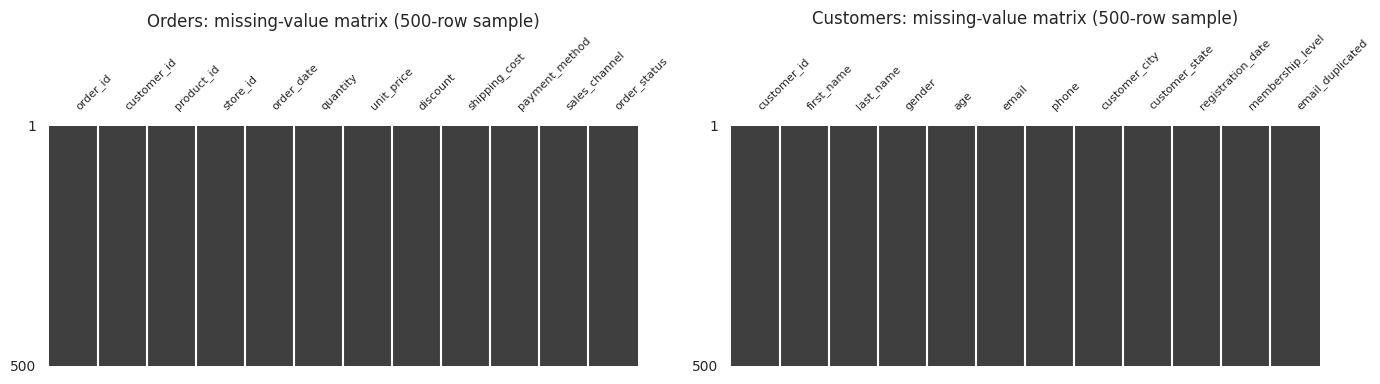

In [7]:
# 3.3 Missing values: true nulls AND hidden placeholders such as "", "N/A", "-"
PLACEHOLDERS = {"", "n/a", "na", "none", "null", "nan", "-", "?"}
rows = []
for name, df in dfs.items():
    nulls = int(df.isna().sum().sum())
    hidden = 0
    for col in df.select_dtypes(include=["object", "string"]).columns:
        hidden += int(df[col].astype(str).str.strip().str.lower().isin(PLACEHOLDERS).sum())
    rows.append({"table": name, "true_nulls": nulls, "hidden_placeholders": hidden})
missing_report = pd.DataFrame(rows)
display(missing_report)
log("3.3", "all", "Checked nulls and placeholder text", "No missing values found, no imputation needed",
    int(missing_report[["true_nulls", "hidden_placeholders"]].sum().sum()))

# Visual confirmation with missingno on the two largest tables
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
msno.matrix(dfs["orders"].sample(500, random_state=1), ax=axes[0], sparkline=False, fontsize=8)
axes[0].set_title("Orders: missing-value matrix (500-row sample)")
msno.matrix(dfs["customers"].sample(500, random_state=1), ax=axes[1], sparkline=False, fontsize=8)
axes[1].set_title("Customers: missing-value matrix (500-row sample)")
save_fig("00_missing_values_check")

A solid column with no white gaps means no missing values. The only "missing-like" values are dirty strings (phone numbers) handled below.

In [8]:
# 3.4 Data types: convert dates, set IDs as text and low-cardinality fields as categories
DATE_COLUMNS = {"customers": ["registration_date"], "orders": ["order_date"], "returns": ["return_date"],
                "employees": ["hire_date"], "stores": ["opening_date"], "inventory": ["last_restock_date"]}
for table, cols in DATE_COLUMNS.items():
    for col in cols:
        converted = pd.to_datetime(dfs[table][col], format="%m/%d/%Y", errors="coerce")
        failed = int(converted.isna().sum())
        dfs[table][col] = converted
        log("3.4", table, f"{col} stored as text (M/D/YYYY)", "Converted to datetime", len(converted) - failed)
        assert failed == 0, f"{table}.{col}: {failed} unparseable dates"

CATEGORICAL = {"customers": ["gender", "membership_level", "customer_state", "customer_city"],
               "orders": ["payment_method", "sales_channel", "order_status"],
               "products": ["category", "sub_category"], "stores": ["region", "store_state"],
               "returns": ["return_reason"], "employees": ["role"], "suppliers": ["country"]}
for table, cols in CATEGORICAL.items():
    for col in cols:
        dfs[table][col] = dfs[table][col].astype(str).str.strip().astype("category")
log("3.4", "7 tables", "Low-cardinality text fields held as plain strings", "Cast to category dtype", 7)

# Money fields must be numeric
money_cols = {"orders": ["unit_price", "discount", "shipping_cost"], "order_items": ["unit_price", "discount", "line_total"],
              "products": ["cost_price", "selling_price"], "returns": ["refund_amount"], "employees": ["monthly_salary"]}
for table, cols in money_cols.items():
    for col in cols:
        assert pd.api.types.is_numeric_dtype(dfs[table][col]), f"{table}.{col} is not numeric"
log("3.4", "5 tables", "Checked currency fields are numeric", "All already numeric, no change", 0)
print("Date range of orders:", dfs["orders"]["order_date"].min().date(), "to", dfs["orders"]["order_date"].max().date())
print("All dates parsed with 0 failures.")

Date range of orders: 2025-01-01 to 2025-12-31
All dates parsed with 0 failures.


In [9]:
# 3.5 Inconsistent values: inspect every categorical field
for table, cols in CATEGORICAL.items():
    for col in cols:
        if col in ("customer_city",):
            continue
        vals = sorted(dfs[table][col].astype(str).unique())
        print(f"{table}.{col:<18} ({len(vals)} values): {vals if len(vals) <= 12 else vals[:12] + ['...']}")

# Phone numbers come in mixed formats (extensions, US-style prefixes). Keep digits only and flag the oddities.
cust = dfs["customers"]
cust["phone_digits"] = cust["phone"].astype(str).str.replace(r"x\d+$", "", regex=True).str.replace(r"\D", "", regex=True)
cust["phone_format_ok"] = cust["phone_digits"].str.len().between(10, 13)
print(f"\nCustomer phone numbers with an unusual length: {(~cust['phone_format_ok']).sum()} of {len(cust)}")
log("3.5", "customers", "Phone numbers in many formats (brackets, dots, extensions)", "Added phone_digits (digits only) and phone_format_ok flag", len(cust))
sup = dfs["suppliers"]
sup["phone_digits"] = sup["phone"].astype(str).str.replace(r"x\d+$", "", regex=True).str.replace(r"\D", "", regex=True)
bad_sup = int((sup["phone_digits"].str.len() < 7).sum())
log("3.5", "suppliers", "Phone values that are too short to be valid (e.g. '-4402')", "Flagged via phone_digits length, kept", bad_sup)
print(f"Supplier phone numbers too short to be valid: {bad_sup}")

customers.gender             (2 values): ['Female', 'Male']
customers.membership_level   (3 values): ['Bronze', 'Gold', 'Silver']
customers.customer_state     (10 values): ['Abuja', 'Anambra', 'Delta', 'Enugu', 'Kaduna', 'Kano', 'Lagos', 'Ogun', 'Oyo', 'Rivers']
orders.payment_method     (3 values): ['Card', 'Cash', 'Transfer']
orders.sales_channel      (2 values): ['In-Store', 'Online']
orders.order_status       (3 values): ['Cancelled', 'Completed', 'Pending']
products.category           (5 values): ['Beauty', 'Electronics', 'Fashion', 'Groceries', 'Home']
products.sub_category       (1 values): ['General']
stores.region             (4 values): ['East', 'North', 'South', 'West']
stores.store_state        (10 values): ['Abuja', 'Anambra', 'Delta', 'Enugu', 'Kaduna', 'Kano', 'Lagos', 'Ogun', 'Oyo', 'Rivers']
returns.return_reason      (4 values): ['Customer Changed Mind', 'Damaged', 'Late Delivery', 'Wrong Item']
employees.role               (5 values): ['Cashier', 'Customer Service', 

Categorical fields are consistent: no spelling variants, no case differences, no stray whitespace. Phone numbers are messy but are not used in any analysis, so they are standardised and flagged rather than altered.

### 3.6 Referential integrity and business-rule checks
Clean *formatting* is not the same as clean *content*. These checks test whether the tables agree with each other and whether the numbers make business sense.

In [10]:
orders, items, products, customers = dfs["orders"], dfs["order_items"], dfs["products"], dfs["customers"]
stores, returns, inventory, suppliers = dfs["stores"], dfs["returns"], dfs["inventory"], dfs["suppliers"]
checks = []
def check(name, n_bad, total, note=""):
    checks.append({"check": name, "records_failing": int(n_bad), "out_of": int(total),
                   "pct_failing": round(100 * n_bad / total, 2), "note": note})

# --- Foreign keys: every child key must exist in its parent table
check("orders.customer_id in customers",  (~orders.customer_id.isin(customers.customer_id)).sum(), len(orders))
check("orders.product_id in products",    (~orders.product_id.isin(products.product_id)).sum(), len(orders))
check("orders.store_id in stores",        (~orders.store_id.isin(stores.store_id)).sum(), len(orders))
check("order_items.order_id in orders",   (~items.order_id.isin(orders.order_id)).sum(), len(items))
check("returns.order_id in orders",       (~returns.order_id.isin(orders.order_id)).sum(), len(returns))
check("inventory.product_id in products", (~inventory.product_id.isin(products.product_id)).sum(), len(inventory))
check("inventory.store_id in stores",     (~inventory.store_id.isin(stores.store_id)).sum(), len(inventory))
check("employees.store_id in stores",     (~dfs["employees"].store_id.isin(stores.store_id)).sum(), len(dfs["employees"]))

# --- Orders vs Order_Items must describe the same transaction
pair = orders.merge(items, on="order_id", suffixes=("", "_item"), validate="1:1")
for col in ["product_id", "quantity", "unit_price", "discount"]:
    check(f"orders vs order_items: {col} agrees", (pair[col] != pair[f"{col}_item"]).sum(), len(pair))

# --- Arithmetic: line_total = quantity x unit_price - discount
calc_flat = items.quantity * items.unit_price - items.discount
calc_pct  = (items.quantity * items.unit_price * (1 - items.discount / 100)).round()
check("line_total = qty x price - discount (flat)", (calc_flat != items.line_total).sum(), len(items))
check("line_total = qty x price x (1 - discount%)", (calc_pct != items.line_total).sum(), len(items),
      "Discount behaves as a flat amount, not a percentage")

# --- Pricing: transaction price vs catalogue
px = orders.merge(products[["product_id", "cost_price", "selling_price"]], on="product_id")
check("order unit_price equals catalogue selling_price", ((px.unit_price - px.selling_price).abs() > 1).sum(), len(px),
      "Order prices are unrelated to catalogue prices")
check("order unit_price below product cost_price", (px.unit_price < px.cost_price).sum(), len(px), "Would mean selling at a loss")
check("catalogue selling_price below cost_price", (products.selling_price < products.cost_price).sum(), len(products))

# --- Returns logic
rx = returns.merge(orders[["order_id", "order_date", "order_status"]], on="order_id") \
            .merge(items[["order_id", "line_total"]], on="order_id")
check("return_date earlier than order_date", (rx.return_date < rx.order_date).sum(), len(rx), "A return before the purchase is impossible")
check("return on a Cancelled or Pending order", (rx.order_status != "Completed").sum(), len(rx), "Only completed orders can be returned")
check("refund_amount larger than line_total", (rx.refund_amount > rx.line_total).sum(), len(rx), "Refund exceeds what was paid")

# --- Customers
oc = orders.merge(customers[["customer_id", "registration_date"]], on="customer_id")
check("order placed before customer registration", (oc.order_date < oc.registration_date).sum(), len(oc))

integrity = pd.DataFrame(checks)
display(integrity)

,check,records_failing,out_of,pct_failing,note
0,orders.customer_id in customers,0,50000,0.00,
1,orders.product_id in products,0,50000,0.00,
2,orders.store_id in stores,0,50000,0.00,
3,order_items.order_id in orders,0,50000,0.00,
4,returns.order_id in orders,0,2500,0.00,
5,inventory.product_id in products,0,500,0.00,
6,inventory.store_id in stores,0,500,0.00,
7,employees.store_id in stores,0,125,0.00,
8,orders vs order_items: product_id agrees,0,50000,0.00,
9,orders vs order_items: quantity agrees,0,50000,0.00,


In [11]:
# Stores: names and regions
print("Store names that appear more than once:", stores.groupby("store_city", observed=True).size().loc[lambda s: s > 1].to_dict())
print("Regions per state (a state should sit in one region):")
display(stores.groupby("store_state", observed=True)["region"].nunique().to_frame("distinct_regions").T)
print("Store_ID is the only reliable store identifier; names and regions repeat.")

# Supplier link: Products has no supplier_id, but supplier_name = brand + ' Supplies'
suppliers["brand"] = suppliers["supplier_name"].str.removesuffix(" Supplies")
print("\nSupplier names that map to a product brand:", round(100 * suppliers["brand"].isin(products["brand"]).mean(), 1), "%")
print("Brands with exactly one supplier:", round(100 * (suppliers.groupby("brand").size() == 1).mean(), 1), "%")

Store names that appear more than once: {'Abeokuta': 2, 'Abuja': 4, 'Asaba': 3, 'Ibadan': 4, 'Kaduna': 3, 'Lagos': 4, 'Port Harcourt': 2}
Regions per state (a state should sit in one region):


store_state,Abuja,Anambra,Delta,Enugu,Kaduna,Kano,Lagos,Ogun,Oyo,Rivers
distinct_regions,3,1,3,1,3,1,4,2,3,1


Store_ID is the only reliable store identifier; names and regions repeat.

Supplier names that map to a product brand: 100.0 %
Brands with exactly one supplier: 100.0 %


In [12]:
# Record the integrity findings in the cleaning log
for _, r in integrity.iterrows():
    if r.records_failing > 0:
        log("3.6", "multiple", r.check + " FAILS", "Flagged in master dataset, rows kept (cause unknown, deletion would distort totals)", r.records_failing)
log("3.6", "all", "Foreign keys checked", "All 8 foreign-key checks passed", 0)
log("3.6", "stores", "Duplicate store names and regions that do not follow geography", "Use store_id as the identifier", 25)
log("3.6", "suppliers", "No supplier_id in products", "Linked via brand = supplier_name minus ' Supplies'", len(suppliers))

### What the integrity checks reveal
* **Structure is sound:** every foreign key resolves, and Orders agree with Order_Items on product, quantity, price and discount.
* **The `discount` column is a flat amount**, not a percentage. `line_total` is reproduced exactly by `quantity x unit_price - discount`. The values (0, 5, 10, 15, 20) look like percentages, so the column name is misleading. This is documented and used consistently.
* **Order prices do not match catalogue prices**, and about a quarter of orders sell below the product's cost price. Margins calculated from transactions are therefore unreliable, so the engineered `profit_margin` uses catalogue prices and a separate transaction-margin field is kept for comparison.
* **Returns have serious logic problems:** about half are dated before the order, most attach to Cancelled or Pending orders, and some refunds exceed the order value. These should be raised with ShopSmart's data owners. Return analysis is shown, but with this caveat.
* **Stores:** names repeat (several "Lagos", "Abuja" stores) and regions do not follow geography, so analysis uses `store_id`.

None of these rows are deleted: they are **flagged** and the analysis states where they matter.

In [13]:
# 3.7 Integrate the tables into one analysis-ready master dataset (one row per order line)
ret_agg = (returns.groupby("order_id", observed=True)
                  .agg(return_count=("return_id", "count"), refund_total=("refund_amount", "sum"),
                       return_reason=("return_reason", "first"), return_date=("return_date", "min"))
                  .reset_index())

prod = products.merge(suppliers[["brand", "supplier_id", "supplier_name", "country"]].rename(columns={"country": "supplier_country"}),
                      on="brand", how="left", validate="m:1")

master = (orders
          .merge(items[["order_id", "order_item_id", "line_total"]], on="order_id", how="left", validate="1:1")
          .merge(prod[["product_id", "product_name", "category", "sub_category", "brand", "cost_price", "selling_price",
                       "supplier_id", "supplier_name", "supplier_country"]], on="product_id", how="left", validate="m:1")
          .merge(customers[["customer_id", "gender", "age", "customer_city", "customer_state", "registration_date", "membership_level"]],
                 on="customer_id", how="left", validate="m:1")
          .merge(stores[["store_id", "store_name", "region", "store_state", "store_city"]], on="store_id", how="left", validate="m:1")
          .merge(ret_agg, on="order_id", how="left"))

master["return_count"] = master["return_count"].fillna(0).astype(int)
master["refund_total"] = master["refund_total"].fillna(0)
master["is_returned"]  = (master["return_count"] > 0).astype(int)

# Data-quality flags carried into the master dataset
master["flag_return_before_order"] = (master["return_date"] < master["order_date"]).astype(int)
master["flag_refund_exceeds_sale"] = (master["refund_total"] > master["line_total"]).astype(int)
master["flag_sold_below_cost"]     = (master["unit_price"] < master["cost_price"]).astype(int)
master["flag_before_registration"] = (master["order_date"] < master["registration_date"]).astype(int)

assert len(master) == len(orders) == 50_000, "Merge changed the number of rows"
assert master["order_id"].is_unique
print("Master dataset:", master.shape)
display(master.head(3).T)

Master dataset: (50000, 42)


,0,1,2
order_id,ORD000001,ORD000002,ORD000003
customer_id,CUST04572,CUST04064,CUST03435
product_id,PROD0244,PROD0432,PROD0052
store_id,STR005,STR010,STR004
order_date,2025-07-19 00:00:00,2025-03-15 00:00:00,2025-10-01 00:00:00
quantity,1,3,2
unit_price,77989,11240,23595
discount,10,5,20
shipping_cost,3833,2872,922
payment_method,Card,Card,Card


In [14]:
# 3.8 Save cleaned tables
for name, df in dfs.items():
    df.to_csv(CLEAN_DIR / f"cleaned_{name}.csv", index=False)
cleaning_log_df = pd.DataFrame(cleaning_log)
cleaning_log_df.to_csv(CLEAN_DIR / "cleaning_log.csv", index=False)
integrity.to_csv(CLEAN_DIR / "integrity_checks.csv", index=False)
print(f"Saved {len(dfs)} cleaned tables, the cleaning log and the integrity report to {CLEAN_DIR}/")
display(cleaning_log_df)

Saved 9 cleaned tables, the cleaning log and the integrity report to Cleaned_Data/


,step,table,issue_found,action_taken,rows_affected
0,3.1,all,Mixed-case column names (e.g. Customer_ID),Converted to lower_snake_case,9
1,3.1,customers / stores,"Ambiguous names (state, city, customer_segment)","Renamed to customer_state/city, store_state/ci...",2
2,3.2,all,Checked full-row and primary-key duplicates,"None found, no rows removed",0
3,3.2,customers,Same email on different customer IDs,"Flagged with email_duplicated, kept",96
4,3.2,returns,Orders with more than one return record (each ...,"Flagged, kept",114
5,3.3,all,Checked nulls and placeholder text,"No missing values found, no imputation needed",0
6,3.4,customers,registration_date stored as text (M/D/YYYY),Converted to datetime,5000
7,3.4,orders,order_date stored as text (M/D/YYYY),Converted to datetime,50000
8,3.4,returns,return_date stored as text (M/D/YYYY),Converted to datetime,2500
9,3.4,employees,hire_date stored as text (M/D/YYYY),Converted to datetime,125


## Part 4: Exploratory Data Analysis
### 4.1 Business KPIs
All revenue figures use **Completed** orders (see assumptions). Gross order value across every status is shown alongside so the effect of that choice is visible.

In [15]:
completed = master[master["order_status"] == "Completed"].copy()

# Inventory joined to product cost and store info (used for inventory value and later restocking analysis)
inv = (inventory.merge(products[["product_id", "product_name", "category", "brand", "cost_price"]], on="product_id", how="left", validate="m:1")
                .merge(stores[["store_id", "store_name", "store_city", "store_state", "region"]], on="store_id", how="left", validate="m:1"))
inv["inventory_value"] = inv["stock_on_hand"] * inv["cost_price"]

K = {
    "total_revenue":      completed["line_total"].sum(),
    "gross_order_value":  master["line_total"].sum(),
    "total_orders":       len(master),
    "completed_orders":   len(completed),
    "total_customers":    customers["customer_id"].nunique(),
    "active_customers":   completed["customer_id"].nunique(),
    "total_products":     products["product_id"].nunique(),
    "products_sold":      completed["product_id"].nunique(),
    "total_stores":       stores["store_id"].nunique(),
    "aov":                completed["line_total"].mean(),
    "avg_selling_price":  completed["unit_price"].mean(),
    "catalogue_avg_price":products["selling_price"].mean(),
    "units_sold":         completed["quantity"].sum(),
    "return_rate":        master["is_returned"].mean(),
    "inventory_value":    inv["inventory_value"].sum(),
}
kpi_table = pd.DataFrame([
    ("Total Revenue (Completed orders)",         money(K["total_revenue"]),       "Sum of line_total, Completed orders only"),
    ("Gross Order Value (all statuses)",         money(K["gross_order_value"]),   "Sum of line_total across all 50,000 orders"),
    ("Total Orders (all statuses)",              f"{K['total_orders']:,}",        "Rows in Orders"),
    ("Completed Orders",                         f"{K['completed_orders']:,}",    "order_status = Completed"),
    ("Total Customers (registered)",             f"{K['total_customers']:,}",     "Unique customer_id in Customers"),
    ("Active Customers (>=1 completed order)",   f"{K['active_customers']:,}",    "Unique customers in Completed orders"),
    ("Total Products (catalogue)",               f"{K['total_products']:,}",      "Unique product_id in Products"),
    ("Products Sold (Completed orders)",         f"{K['products_sold']:,}",       "Unique products in Completed orders"),
    ("Total Stores",                             f"{K['total_stores']:,}",        "Unique store_id in Stores"),
    ("Average Order Value (AOV)",                money(K["aov"]),                 "Revenue / completed orders"),
    ("Average Selling Price (per unit sold)",    money(K["avg_selling_price"]),   "Mean unit_price on Completed orders"),
    ("Average Catalogue Selling Price",          money(K["catalogue_avg_price"]), "Mean selling_price in Products"),
    ("Total Quantity Sold (units)",              f"{K['units_sold']:,}",          "Sum of quantity, Completed orders"),
    ("Return Rate",                              f"{K['return_rate']:.2%}",       "Orders with a return / all orders"),
    ("Inventory Value (at cost)",                money(K["inventory_value"]),     "Sum of stock_on_hand x cost_price"),
], columns=["KPI", "Value", "Definition"])
display(kpi_table)
kpi_table.to_csv(CLEAN_DIR / "kpi_summary.csv", index=False)

,KPI,Value,Definition
0,Total Revenue (Completed orders),NGN 2.50B,"Sum of line_total, Completed orders only"
1,Gross Order Value (all statuses),NGN 7.58B,"Sum of line_total across all 50,000 orders"
2,Total Orders (all statuses),"50,000",Rows in Orders
3,Completed Orders,"16,529",order_status = Completed
4,Total Customers (registered),"5,000",Unique customer_id in Customers
5,Active Customers (>=1 completed order),"4,795",Unique customers in Completed orders
6,Total Products (catalogue),500,Unique product_id in Products
7,Products Sold (Completed orders),500,Unique products in Completed orders
8,Total Stores,25,Unique store_id in Stores
9,Average Order Value (AOV),NGN 151K,Revenue / completed orders


In [16]:
# 4.2 How orders break down by status, channel and payment method
status = master.groupby("order_status", observed=True).agg(orders=("order_id", "count"), order_value=("line_total", "sum"))
status["share_of_orders"] = (status["orders"] / status["orders"].sum()).map("{:.1%}".format)
status["order_value"] = status["order_value"].map(money)
display(status)
print("Only about one in three orders is Completed, so the revenue definition matters a great deal.\n")
for col in ["sales_channel", "payment_method"]:
    display(completed.groupby(col, observed=True)["line_total"].agg(orders="count", revenue="sum", avg_order="mean")
            .assign(revenue=lambda d: d["revenue"].map(money), avg_order=lambda d: d["avg_order"].map(money)))

,orders,order_value,share_of_orders
order_status,,,
Cancelled,16861,NGN 2.55B,33.7%
Completed,16529,NGN 2.50B,33.1%
Pending,16610,NGN 2.53B,33.2%


Only about one in three orders is Completed, so the revenue definition matters a great deal.



,orders,revenue,avg_order
sales_channel,,,
In-Store,8260,NGN 1.26B,NGN 152K
Online,8269,NGN 1.24B,NGN 150K


,orders,revenue,avg_order
payment_method,,,
Card,5372,NGN 819.7M,NGN 153K
Cash,5615,NGN 849.5M,NGN 151K
Transfer,5542,NGN 827.6M,NGN 149K


In [17]:
# 4.3 Descriptive statistics and distribution shape
num_cols = ["quantity", "unit_price", "discount", "shipping_cost", "line_total"]
desc = completed[num_cols].describe().T
desc["skewness"] = completed[num_cols].skew()
desc["cv_%"] = 100 * desc["std"] / desc["mean"]
display(desc)

# Outliers via the 1.5 x IQR rule
rows = []
for c in ["unit_price", "shipping_cost", "line_total"]:
    q1, q3 = completed[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = ((completed[c] < q1 - 1.5 * iqr) | (completed[c] > q3 + 1.5 * iqr)).sum()
    rows.append({"variable": c, "lower_fence": q1 - 1.5 * iqr, "upper_fence": q3 + 1.5 * iqr,
                 "outliers": int(n_out), "pct": f"{n_out / len(completed):.2%}"})
display(pd.DataFrame(rows))

,count,mean,std,min,25%,50%,75%,max,skewness,cv_%
quantity,"16,529.00",2.99,1.42,1.00,2.00,3.00,4.00,5.00,0.00,47.39
unit_price,"16,529.00","50,364.42","28,679.43","1,027.00","25,440.00","50,543.00","75,166.00","99,998.00",-0.01,56.94
discount,"16,529.00",10.01,7.07,0.00,5.00,10.00,15.00,20.00,-0.00,70.62
shipping_cost,"16,529.00","2,756.76","1,293.55",500.00,"1,643.00","2,770.00","3,876.00","5,000.00",-0.01,46.92
line_total,"16,529.00","151,057.20","118,807.44","1,014.00","55,527.00","118,466.00","227,161.00","499,915.00",0.87,78.65


,variable,lower_fence,upper_fence,outliers,pct
0,unit_price,"-49,149.00","149,755.00",0,0.00%
1,shipping_cost,"-1,706.50","7,225.50",0,0.00%
2,line_total,"-201,924.00","484,612.00",101,0.61%


**Reading the statistics:** `quantity` is spread evenly from 1 to 5 and `discount` takes five fixed values, which is unusually uniform for real retail data. `line_total` is right-skewed (a few large orders pull the mean above the median), so the **median** is a better "typical order" measure than the mean. Outliers under the IQR rule are listed above; they are high-value orders, not data errors, and are kept.

### 4.4 Do the differences we see actually matter? (statistical tests)
Rankings of stores, categories or segments always have a "top" and a "bottom", even when the gaps are just random noise. Two quick tests check whether the gaps are real.

In [18]:
def verdict(p, alpha=0.05):
    return "statistically significant difference" if p < alpha else "NO significant difference (consistent with random variation)"

# Kruskal-Wallis: does revenue per order differ across groups? (non-parametric, suits skewed money data)
tests = []
for label, col in [("Store", "store_id"), ("Category", "category"), ("Membership level", "membership_level"),
                   ("Region", "region"), ("Sales channel", "sales_channel")]:
    groups = [g["line_total"].values for _, g in completed.groupby(col, observed=True)]
    h, p = stats.kruskal(*groups)
    tests.append({"test": f"Kruskal-Wallis: order value by {label}", "statistic": round(h, 2), "p_value": round(p, 4), "conclusion": verdict(p)})

# Chi-square: is the chance of a return linked to category / channel / store?
for label, col in [("Category", "category"), ("Sales channel", "sales_channel"), ("Store", "store_id")]:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(master[col], master["is_returned"]))
    tests.append({"test": f"Chi-square: return rate by {label}", "statistic": round(chi2, 2), "p_value": round(p, 4), "conclusion": verdict(p)})
stat_tests = pd.DataFrame(tests)
display(stat_tests)
stat_tests.to_csv(CLEAN_DIR / "statistical_tests.csv", index=False)

,test,statistic,p_value,conclusion
0,Kruskal-Wallis: order value by Store,27.50,0.28,NO significant difference (consistent with ran...
1,Kruskal-Wallis: order value by Category,2.08,0.72,NO significant difference (consistent with ran...
2,Kruskal-Wallis: order value by Membership level,0.70,0.71,NO significant difference (consistent with ran...
3,Kruskal-Wallis: order value by Region,5.46,0.14,NO significant difference (consistent with ran...
4,Kruskal-Wallis: order value by Sales channel,2.48,0.12,NO significant difference (consistent with ran...
5,Chi-square: return rate by Category,4.41,0.35,NO significant difference (consistent with ran...
6,Chi-square: return rate by Sales channel,1.31,0.25,NO significant difference (consistent with ran...
7,Chi-square: return rate by Store,28.45,0.24,NO significant difference (consistent with ran...


**Result:** none of the eight tests found a significant difference. Every p-value is above 0.05 (the smallest is 0.12, for sales channel). In plain terms, stores, categories, regions, membership levels and sales channels all behave almost identically in order value, and return rates do not differ by category, channel or store.

**What this means for the rest of the notebook:** the rankings that follow (best store, top category, and so on) describe *scale and luck of the draw* more than genuine differences in quality. They are still worth reporting, but conclusions drawn from them will be worded cautiously.

## Part 5: Data Visualisation
Ten required charts, each saved as a PNG in `Visualizations/`. Revenue charts use Completed orders; amounts are in NGN (assumed).

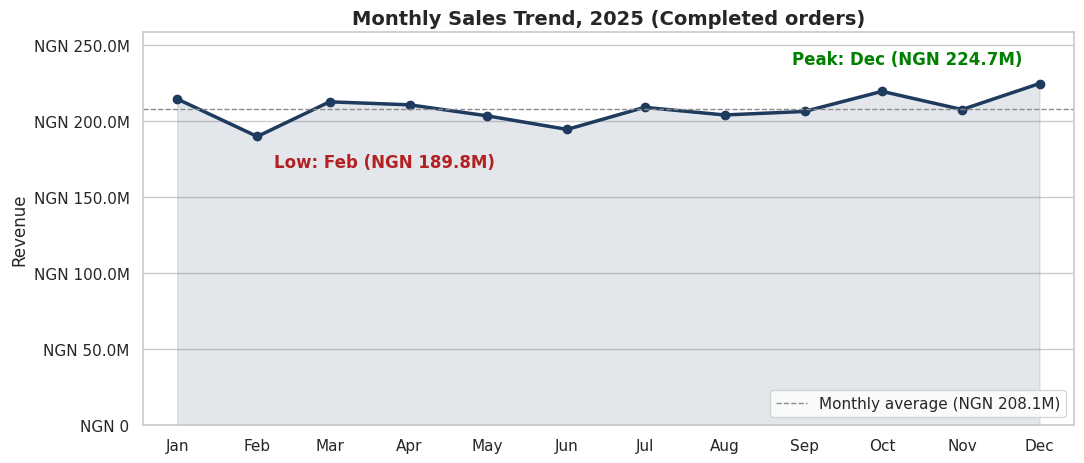

In [19]:
# Chart 1: Monthly sales trend
monthly = (completed.assign(month=completed["order_date"].dt.to_period("M").dt.to_timestamp())
                    .groupby("month").agg(revenue=("line_total", "sum"), orders=("order_id", "count")).reset_index())
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(monthly["month"], monthly["revenue"], marker="o", lw=2.5, color=BRAND_BLUE)
ax.fill_between(monthly["month"], monthly["revenue"], alpha=.12, color=BRAND_BLUE)
hi, lo = monthly.loc[monthly["revenue"].idxmax()], monthly.loc[monthly["revenue"].idxmin()]
ax.annotate(f"Peak: {hi.month:%b} ({money(hi.revenue)})", (hi.month, hi.revenue), textcoords="offset points", xytext=(-12, 14), ha="right", color="green", fontweight="bold")
ax.annotate(f"Low: {lo.month:%b} ({money(lo.revenue)})",  (lo.month, lo.revenue), textcoords="offset points", xytext=(12, -22), ha="left", color="firebrick", fontweight="bold")
avg = monthly["revenue"].mean()
ax.axhline(avg, ls="--", color=GREY, lw=1, label=f"Monthly average ({money(avg)})")
ax.yaxis.set_major_formatter(money_axis); ax.set_xticks(monthly["month"]); ax.set_xticklabels(monthly["month"].dt.strftime("%b"))
ax.grid(axis="x", visible=False); ax.margins(x=0.04); ax.legend(loc="lower right")
ax.set_title("Monthly Sales Trend, 2025 (Completed orders)", fontsize=14, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("Revenue")
ax.set_ylim(0, monthly["revenue"].max() * 1.15)
save_fig("01_monthly_sales_trend")

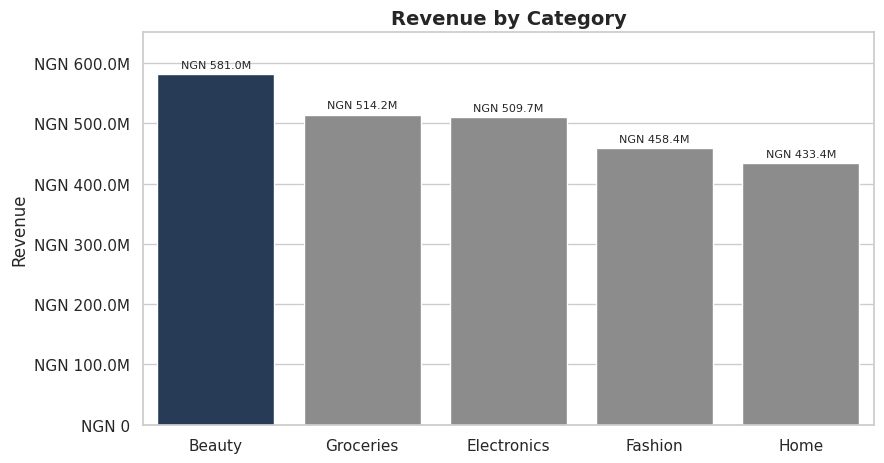

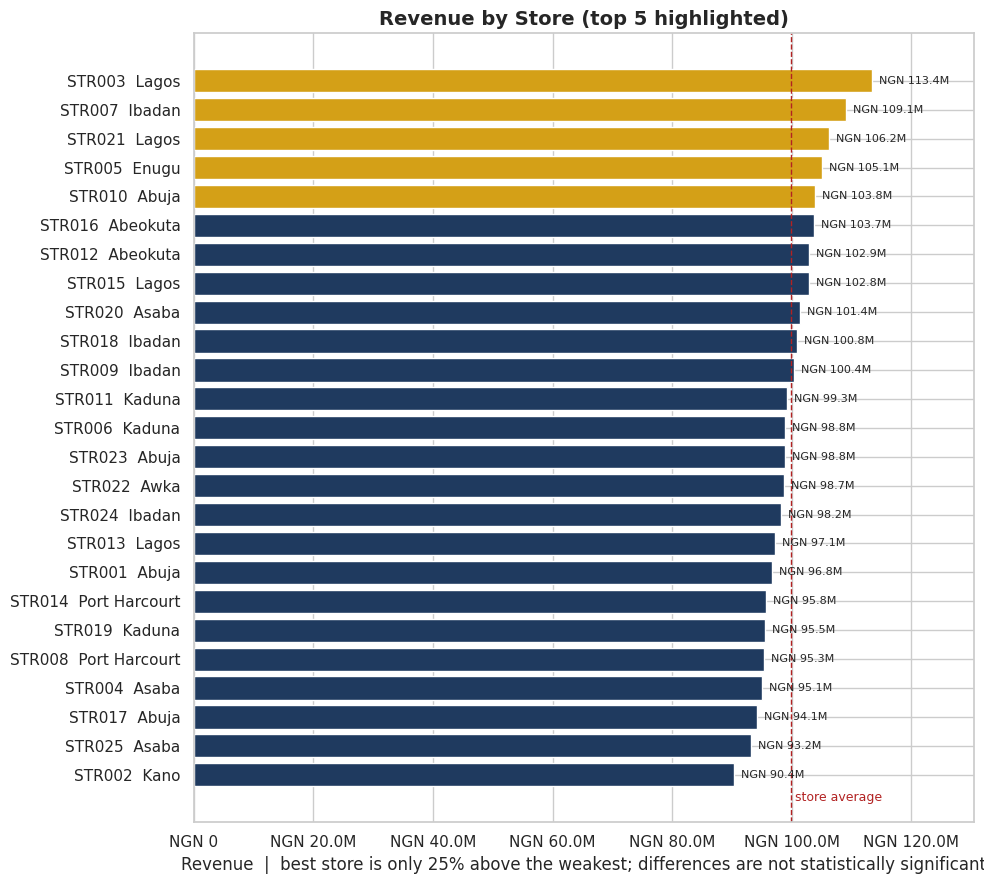

In [20]:
# Chart 2: Revenue by category
cat_rev = completed.groupby("category", observed=True)["line_total"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.barplot(x=cat_rev.index.astype(str), y=cat_rev.values, hue=cat_rev.index.astype(str), palette=[BRAND_BLUE] + [GREY] * (len(cat_rev) - 1), legend=False, ax=ax)
bar_labels(ax); ax.yaxis.set_major_formatter(money_axis)
ax.set_title("Revenue by Category", fontsize=14, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("Revenue"); ax.set_ylim(0, cat_rev.max() * 1.12)
save_fig("02_revenue_by_category")

# Chart 3: Revenue by store (25 stores; top 5 highlighted)
store_rev = completed.groupby(["store_id", "store_city"], observed=True)["line_total"].sum().reset_index()
store_rev["label"] = store_rev["store_id"] + "  " + store_rev["store_city"].astype(str)
store_rev = store_rev.sort_values("line_total")
fig, ax = plt.subplots(figsize=(10, 9))
colors = [BRAND_GOLD if i >= len(store_rev) - 5 else BRAND_BLUE for i in range(len(store_rev))]
ax.barh(store_rev["label"], store_rev["line_total"], color=colors)
ax.xaxis.set_major_formatter(money_axis); ax.axvline(store_rev["line_total"].mean(), ls="--", color="firebrick", lw=1)
ax.text(store_rev["line_total"].mean(), -0.9, " store average", color="firebrick", fontsize=9)
for y, v in enumerate(store_rev["line_total"]): ax.text(v, y, "  " + money(v), va="center", fontsize=8)
spread = store_rev["line_total"].max() / store_rev["line_total"].min() - 1
ax.set_xlim(0, store_rev["line_total"].max() * 1.15)
ax.set_title("Revenue by Store (top 5 highlighted)", fontsize=14, fontweight="bold")
ax.set_xlabel(f"Revenue  |  best store is only {spread:.0%} above the weakest; differences are not statistically significant")
save_fig("03_revenue_by_store")

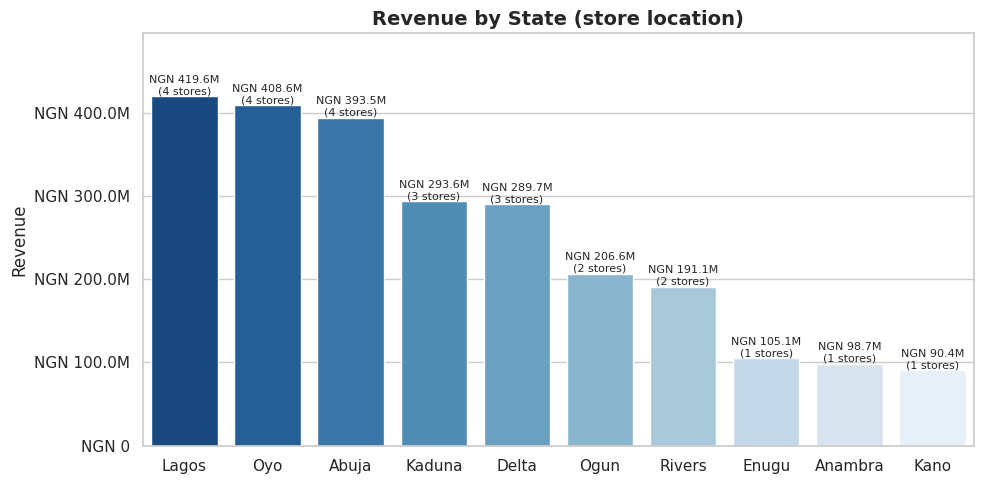

,revenue,stores,revenue_per_store
store_state,,,
Lagos,NGN 419.6M,4,NGN 104.9M
Oyo,NGN 408.6M,4,NGN 102.1M
Abuja,NGN 393.5M,4,NGN 98.4M
Kaduna,NGN 293.6M,3,NGN 97.9M
Delta,NGN 289.7M,3,NGN 96.6M
Ogun,NGN 206.6M,2,NGN 103.3M
Rivers,NGN 191.1M,2,NGN 95.5M
Enugu,NGN 105.1M,1,NGN 105.1M
Anambra,NGN 98.7M,1,NGN 98.7M


In [21]:
# Chart 4: Revenue by state (state of the store)
state_rev = completed.groupby("store_state", observed=True).agg(revenue=("line_total", "sum"), stores=("store_id", "nunique")).sort_values("revenue", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=state_rev.index.astype(str), y=state_rev["revenue"], hue=state_rev.index.astype(str), palette="Blues_r", legend=False, ax=ax)
for i, (idx, r) in enumerate(state_rev.iterrows()):
    ax.text(i, r["revenue"], f"{money(r['revenue'])}\n({int(r['stores'])} stores)", ha="center", va="bottom", fontsize=8)
ax.yaxis.set_major_formatter(money_axis); ax.set_ylim(0, state_rev["revenue"].max() * 1.18)
ax.set_title("Revenue by State (store location)", fontsize=14, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("Revenue")
save_fig("04_revenue_by_state")
display(state_rev.assign(revenue_per_store=lambda d: (d["revenue"] / d["stores"]).map(money), revenue=lambda d: d["revenue"].map(money)))

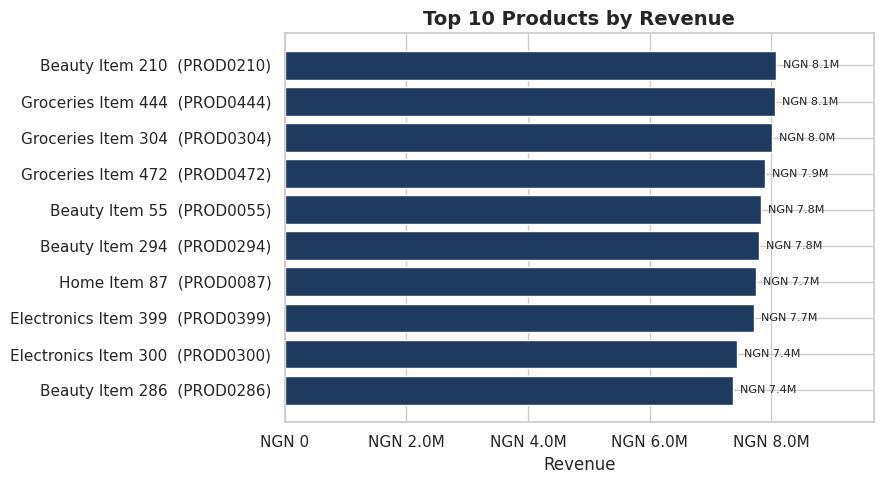

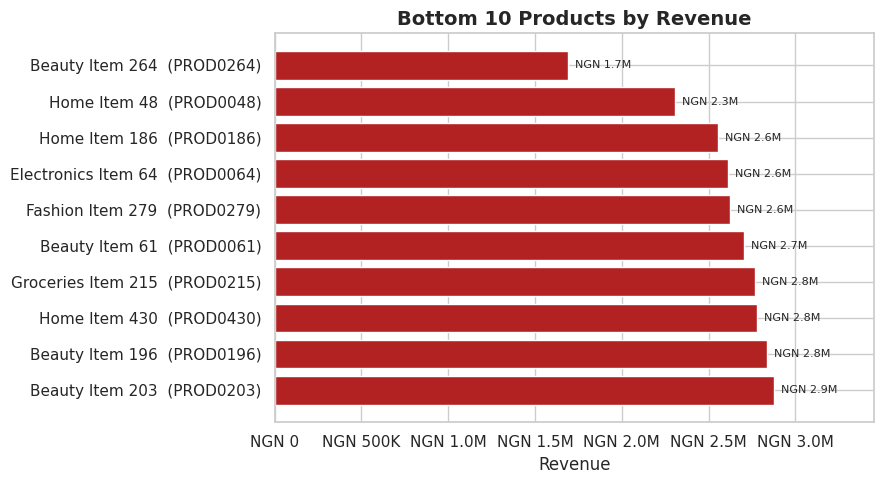

Top product earns NGN 8.1M; bottom product earns NGN 1.7M; the median product earns NGN 4.9M.


In [22]:
# Charts 5 and 6: Top 10 and Bottom 10 products
prod_rev = completed.groupby(["product_id", "product_name", "category"], observed=True)["line_total"].sum().reset_index().sort_values("line_total", ascending=False)
top10, bottom10 = prod_rev.head(10).iloc[::-1], prod_rev.tail(10)
for data, title, color, fname in [(top10, "Top 10 Products by Revenue", BRAND_BLUE, "05_top10_products"),
                                  (bottom10, "Bottom 10 Products by Revenue", "firebrick", "06_bottom10_products")]:
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(data["product_name"] + "  (" + data["product_id"] + ")", data["line_total"], color=color)
    for y, v in enumerate(data["line_total"]): ax.text(v, y, "  " + money(v), va="center", fontsize=8)
    ax.xaxis.set_major_formatter(money_axis); ax.set_xlim(0, data["line_total"].max() * 1.2)
    ax.set_title(title, fontsize=14, fontweight="bold"); ax.set_xlabel("Revenue")
    save_fig(fname)
print(f"Top product earns {money(prod_rev['line_total'].max())}; bottom product earns {money(prod_rev['line_total'].min())}; "
      f"the median product earns {money(prod_rev['line_total'].median())}.")

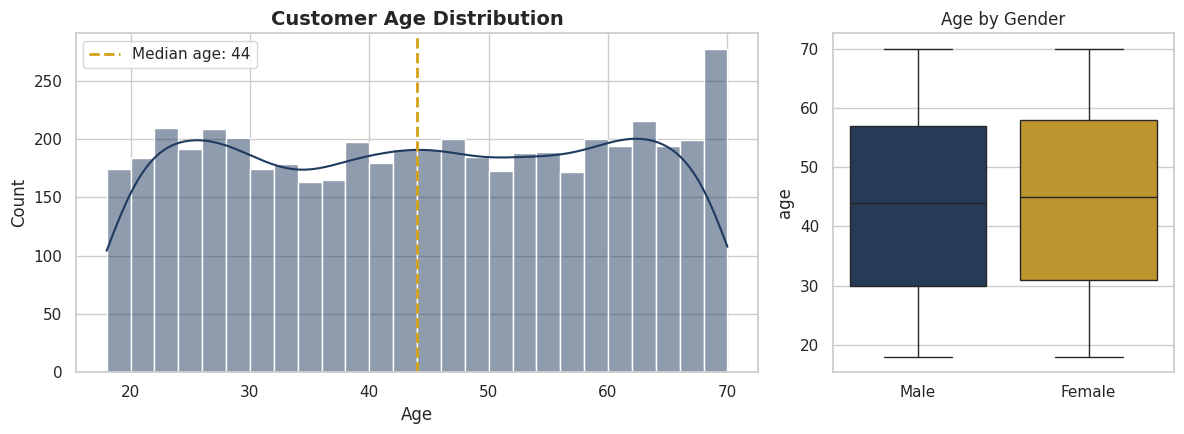

{'count': 5000.0, 'mean': 44.2, 'std': 15.4, 'min': 18.0, '25%': 30.0, '50%': 44.0, '75%': 58.0, 'max': 70.0}


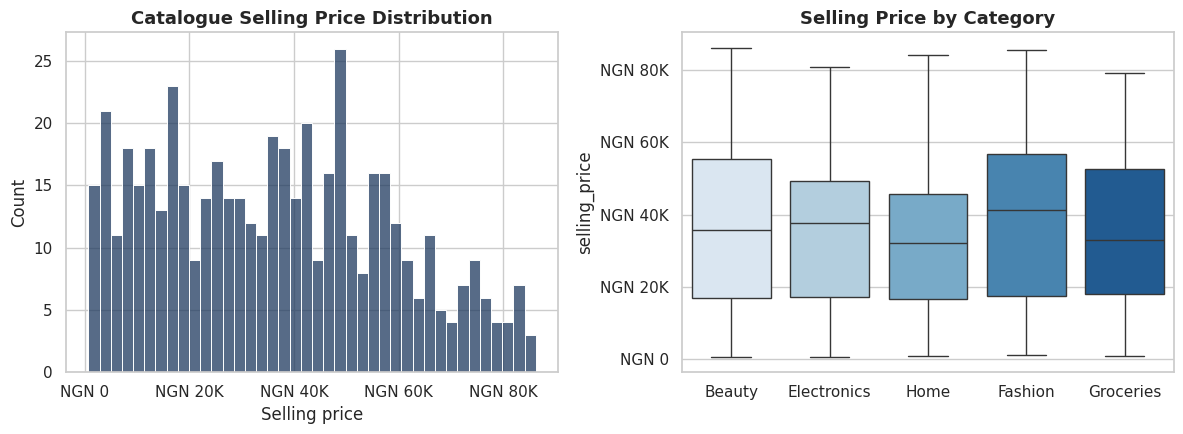

In [23]:
# Chart 7: Customer age distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [2, 1]})
sns.histplot(customers["age"], bins=range(18, 72, 2), kde=True, color=BRAND_BLUE, ax=axes[0])
axes[0].axvline(customers["age"].median(), color=BRAND_GOLD, lw=2, ls="--", label=f"Median age: {customers['age'].median():.0f}")
axes[0].set_title("Customer Age Distribution", fontsize=14, fontweight="bold"); axes[0].set_xlabel("Age"); axes[0].legend()
sns.boxplot(x=customers["gender"].astype(str), y=customers["age"], hue=customers["gender"].astype(str), palette=[BRAND_BLUE, BRAND_GOLD], legend=False, ax=axes[1])
axes[1].set_title("Age by Gender"); axes[1].set_xlabel("")
save_fig("07_customer_age_distribution")
print(customers["age"].describe().round(1).to_dict())

# Chart 8: Product price distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(products["selling_price"], bins=40, color=BRAND_BLUE, ax=axes[0])
axes[0].xaxis.set_major_formatter(money_axis); axes[0].set_title("Catalogue Selling Price Distribution", fontsize=13, fontweight="bold"); axes[0].set_xlabel("Selling price")
sns.boxplot(x="category", y="selling_price", data=products.assign(category=products["category"].astype(str)), hue="category", palette="Blues", legend=False, ax=axes[1])
axes[1].yaxis.set_major_formatter(money_axis); axes[1].set_title("Selling Price by Category", fontsize=13, fontweight="bold"); axes[1].set_xlabel("")
save_fig("08_product_price_distribution")

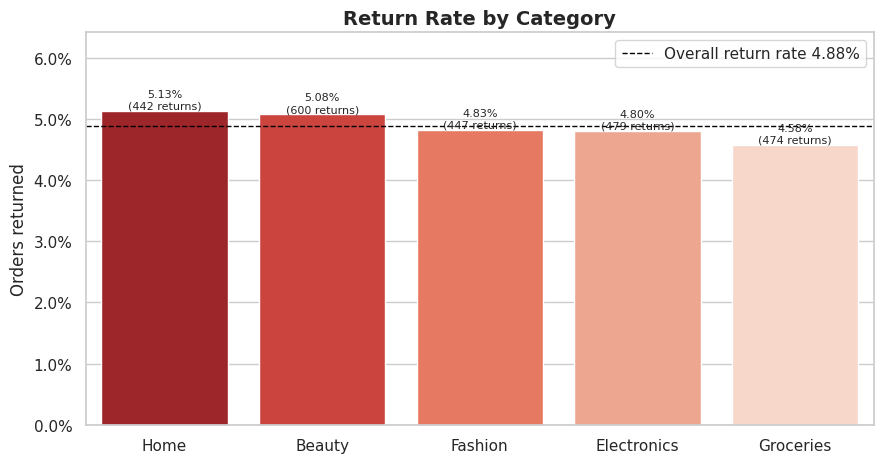

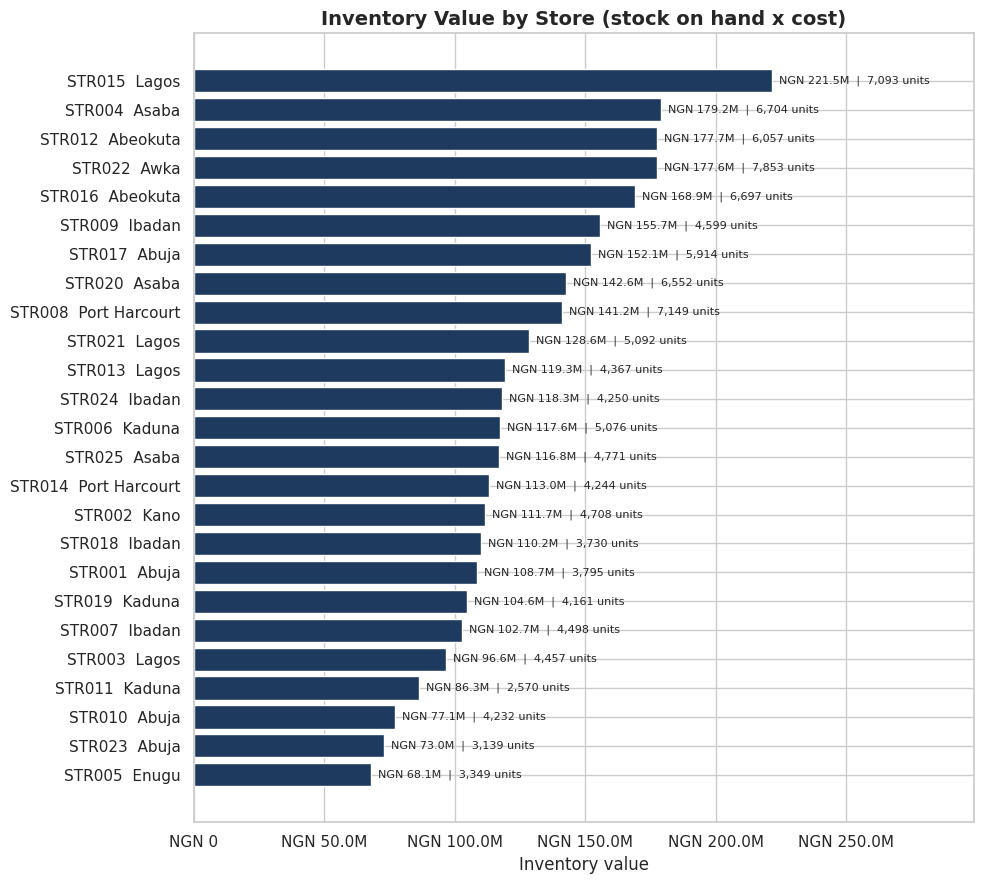

In [24]:
# Chart 9: Return rate by category
ret_cat = master.groupby("category", observed=True)["is_returned"].agg(rate="mean", returned="sum", orders="count").sort_values("rate", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.barplot(x=ret_cat.index.astype(str), y=ret_cat["rate"] * 100, hue=ret_cat.index.astype(str), palette="Reds_r", legend=False, ax=ax)
for i, r in enumerate(ret_cat.itertuples()): ax.text(i, r.rate * 100, f"{r.rate:.2%}\n({int(r.returned)} returns)", ha="center", va="bottom", fontsize=8)
ax.axhline(K["return_rate"] * 100, color="black", ls="--", lw=1, label=f"Overall return rate {K['return_rate']:.2%}"); ax.legend(loc="upper right")
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, ret_cat["rate"].max() * 100 * 1.25)
ax.set_title("Return Rate by Category", fontsize=14, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("Orders returned")
save_fig("09_return_rate_by_category")

# Chart 10: Inventory by store
inv_store = inv.groupby(["store_id", "store_city"], observed=True).agg(units=("stock_on_hand", "sum"), value=("inventory_value", "sum"), skus=("product_id", "count")).reset_index()
inv_store["label"] = inv_store["store_id"] + "  " + inv_store["store_city"].astype(str)
inv_store = inv_store.sort_values("value")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(inv_store["label"], inv_store["value"], color=BRAND_BLUE)
for y, (v, u) in enumerate(zip(inv_store["value"], inv_store["units"])): ax.text(v, y, f"  {money(v)}  |  {u:,} units", va="center", fontsize=8)
ax.xaxis.set_major_formatter(money_axis); ax.set_xlim(0, inv_store["value"].max() * 1.35)
ax.set_title("Inventory Value by Store (stock on hand x cost)", fontsize=14, fontweight="bold"); ax.set_xlabel("Inventory value")
save_fig("10_inventory_by_store")

### What the ten charts show
* **Monthly trend:** revenue is steady at roughly NGN 208M a month. December peaks (NGN 224.7M) and February is lowest (NGN 189.8M), but February has only 28 days, so part of that dip is simply calendar length.
* **Category:** Beauty leads (NGN 581M, 23.3% of revenue) and Home is lowest (NGN 433M). Beauty also has the largest catalogue, which matters (see Q1).
* **Store:** STR003 (Lagos) is highest at NGN 113.4M and STR002 (Kano) lowest at NGN 90.4M. Most stores sit close to the average.
* **State:** Lagos, Oyo and Abuja lead, but each has four stores. Revenue per store is almost flat across states (about NGN 90M to 105M), so the ranking mostly follows how many stores a state has.
* **Top and bottom products:** the best product earns NGN 8.1M, the weakest NGN 1.7M and the median NGN 4.9M. No product dominates.
* **Customer age:** customers are aged 18 to 70 with a median of 44, spread fairly evenly. Men and women have almost the same age profile.
* **Price distribution:** catalogue prices run from about NGN 1K to NGN 86K with similar spreads in every category.
* **Return rate:** all categories sit between 4.6% (Groceries) and 5.1% (Home), close to the 4.88% overall rate.
* **Inventory by store:** stock value is uneven, from NGN 68M (STR005 Enugu) to NGN 221M (STR015 Lagos), against a store average of NGN 127M.

## Part 6: Correlation Analysis
Pearson correlation measures **linear** association between numeric variables (-1 to +1). A value near 0 means no linear relationship. Variables that are calculated from each other (such as `line_total` from `quantity` x `unit_price`) are expected to correlate, so we separate those "mechanical" links from genuine behavioural ones.

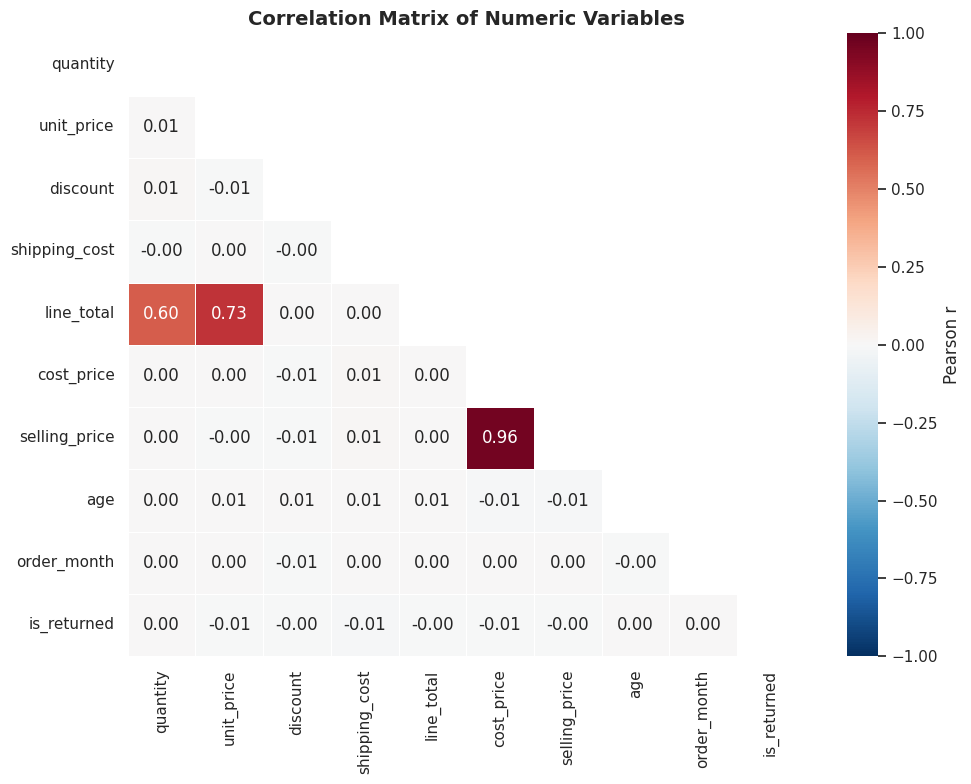

Strongest relationships:


,variable_1,variable_2,r
65,selling_price,cost_price,0.96
41,line_total,unit_price,0.73
40,line_total,quantity,0.60
63,selling_price,shipping_cost,0.01
53,cost_price,shipping_cost,0.01
20,discount,quantity,0.01


Weakest relationships (closest to zero):


,variable_1,variable_2,r
30,shipping_cost,quantity,-0.00
51,cost_price,unit_price,0.00
61,selling_price,unit_price,-0.00
87,order_month,age,-0.00
70,age,quantity,0.00
54,cost_price,line_total,0.00


In [25]:
corr_cols = ["quantity", "unit_price", "discount", "shipping_cost", "line_total", "cost_price", "selling_price", "age", "order_month", "is_returned"]
corr_df = master.assign(order_month=master["order_date"].dt.month)[corr_cols]
corr = corr_df.corr(method="pearson")

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.5, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.grid(False); ax.set_title("Correlation Matrix of Numeric Variables", fontsize=14, fontweight="bold")
save_fig("11_correlation_heatmap")

pairs = corr.where(np.tril(np.ones(corr.shape), k=-1).astype(bool)).stack().reset_index()
pairs.columns = ["variable_1", "variable_2", "r"]; pairs["abs_r"] = pairs["r"].abs()
print("Strongest relationships:"); display(pairs.sort_values("abs_r", ascending=False).head(6).drop(columns="abs_r"))
print("Weakest relationships (closest to zero):"); display(pairs.sort_values("abs_r").head(6).drop(columns="abs_r"))

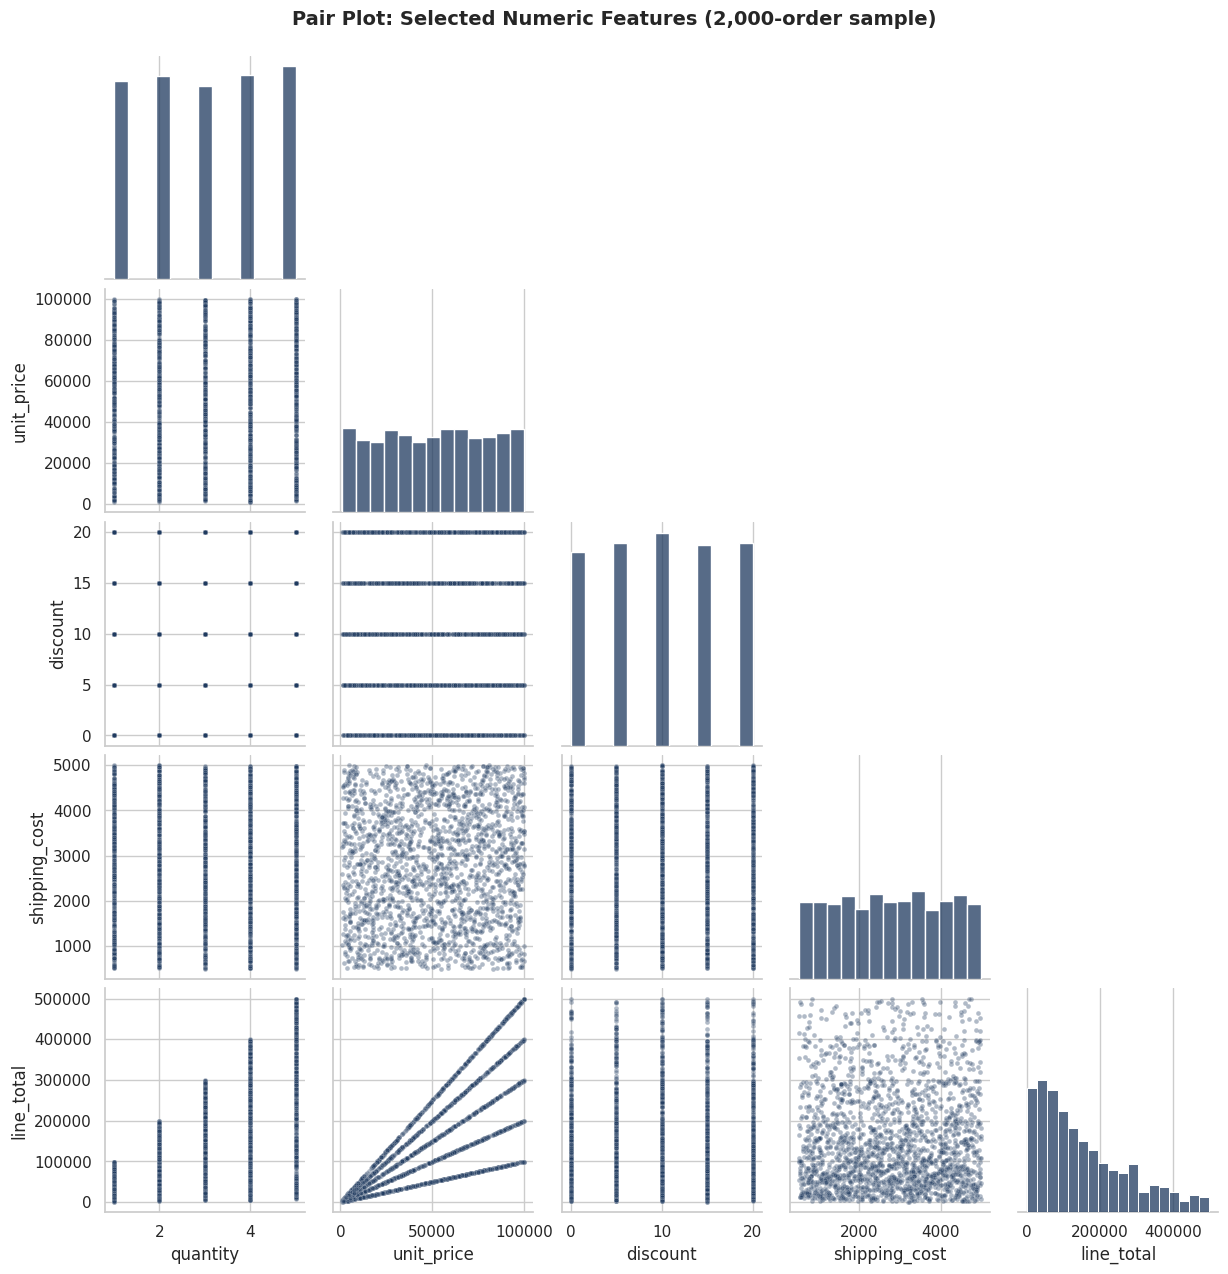

In [26]:
# Pair plot of selected numeric features (2,000-row random sample keeps it readable and fast)
pp_cols = ["quantity", "unit_price", "discount", "shipping_cost", "line_total"]
g = sns.pairplot(master[pp_cols].sample(2000, random_state=42), corner=True, diag_kind="hist",
                 plot_kws={"alpha": .35, "s": 12, "color": BRAND_BLUE}, diag_kws={"color": BRAND_BLUE})
g.figure.suptitle("Pair Plot: Selected Numeric Features (2,000-order sample)", y=1.02, fontsize=14, fontweight="bold")
g.savefig(VIZ_DIR / "12_pairplot_selected_features.png", dpi=130, bbox_inches="tight")
plt.show()

### Reading the correlation results
**Which variables are strongly correlated?**
* `selling_price` and `cost_price` (r = 0.96): products are priced as a consistent mark-up over cost.
* `line_total` with `unit_price` (r = 0.73) and with `quantity` (r = 0.60). These links are *mechanical*, because `line_total` is calculated from price and quantity.

**Which variables appear unrelated?**
Everything else sits at |r| <= 0.01: shipping cost, discount, customer age, order month and the return flag do not move with price, quantity or spend. Two unrelated pairs deserve special mention. The price charged on an order has **no relationship to the catalogue price** (r = 0.00), and the **return flag is unrelated to every numeric variable**. The pair plot agrees: it shows flat, even scatter with no hidden curved patterns.

**How could these relationships be useful?**
1. The price-cost link confirms margin features built from catalogue prices are sound.
2. Because `line_total` is built from `quantity` and `unit_price`, predicting order value is trivial, and using `line_total` as an input to predict itself would be data leakage in any future model.
3. Near-zero correlations warn us that linear models will struggle to predict returns or spend from these attributes. Better results would need new data (delivery times, customer reviews, promotions) rather than more modelling effort.

*Pearson correlation only captures linear relationships; Q10 tests a non-linear model as well.*

## Part 7: Feature Engineering
New features are built at three levels: **order** (one row per order), **customer** (one row per customer) and **inventory** (one row per product-store stock record). They are wrapped in functions so the same logic can be re-run on new data.

In [27]:
REF_DATE = master["order_date"].max()          # "today" for recency calculations = last day of the data
LIFESPAN_YEARS = 3                             # assumption used for the CLV approximation
AGE_BINS   = [17, 24, 34, 44, 54, 64, 120]
AGE_LABELS = ["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]

def engineer_order_features(df):
    # Order-level features: time, money, margin and customer context.
    d = df.copy()
    d["order_year"]       = d["order_date"].dt.year
    d["order_month"]      = d["order_date"].dt.month
    d["order_month_name"] = d["order_date"].dt.strftime("%b")
    d["order_quarter"]    = "Q" + d["order_date"].dt.quarter.astype(str)
    d["order_weekday"]    = d["order_date"].dt.day_name()
    d["is_weekend"]       = (d["order_date"].dt.dayofweek >= 5).astype(int)
    d["gross_amount"]     = d["quantity"] * d["unit_price"]
    d["discount_pct"]     = 100 * d["discount"] / d["gross_amount"]                 # effective discount as % of gross
    d["order_total_incl_shipping"] = d["line_total"] + d["shipping_cost"]
    d["profit_margin_pct"] = 100 * (d["selling_price"] - d["cost_price"]) / d["selling_price"]   # catalogue margin
    d["txn_margin_pct"]    = 100 * (d["unit_price"] - d["cost_price"]) / d["unit_price"]         # margin at the price actually charged
    d["customer_age_group"] = pd.cut(d["age"], bins=AGE_BINS, labels=AGE_LABELS)
    d["customer_tenure_days_at_order"] = (d["order_date"] - d["registration_date"]).dt.days
    return d

def engineer_customer_features(orders_df, customers_df, ref_date, lifespan_years=LIFESPAN_YEARS):
    # Customer-level features: RFM, return behaviour and an approximate lifetime value.
    done = orders_df[orders_df["order_status"] == "Completed"]
    out = customers_df[["customer_id", "gender", "age", "customer_state", "membership_level", "registration_date"]].copy()
    out["customer_age_group"] = pd.cut(out["age"], bins=AGE_BINS, labels=AGE_LABELS)
    all_agg  = orders_df.groupby("customer_id").agg(orders_placed=("order_id", "count"), orders_returned=("is_returned", "sum"))
    done_agg = done.groupby("customer_id").agg(completed_orders=("order_id", "count"), total_spend=("line_total", "sum"),
                                               units_bought=("quantity", "sum"), first_purchase=("order_date", "min"), last_purchase=("order_date", "max"))
    out = out.merge(all_agg, on="customer_id", how="left").merge(done_agg, on="customer_id", how="left")
    for c in ["orders_placed", "orders_returned", "completed_orders", "total_spend", "units_bought"]:
        out[c] = out[c].fillna(0)
    out["has_purchased"]            = (out["completed_orders"] > 0).astype(int)
    out["avg_order_value"]          = out["total_spend"] / out["completed_orders"].replace(0, np.nan)
    out["days_since_last_purchase"] = (ref_date - out["last_purchase"]).dt.days
    out["customer_tenure_days"]     = (ref_date - out["registration_date"]).dt.days
    out["return_rate"]              = out["orders_returned"] / out["orders_placed"].replace(0, np.nan)
    # CLV approximation = average order value x purchases per year x assumed lifespan (data covers one year)
    out["clv_approx"]               = out["avg_order_value"].fillna(0) * out["completed_orders"] * lifespan_years
    return out

def engineer_inventory_features(inv_df):
    # Inventory-level features: stock cover and a Low / Medium / High status.
    out = inv_df.copy()
    out["stock_cover_ratio"]   = out["stock_on_hand"] / out["reorder_level"]
    out["inventory_status"]    = pd.cut(out["stock_cover_ratio"], bins=[0, 1, 5, np.inf], labels=["Low", "Medium", "High"])
    out["units_below_reorder"] = (out["reorder_level"] - out["stock_on_hand"]).clip(lower=0)
    out["days_since_restock"]  = (out["last_restock_date"].max() - out["last_restock_date"]).dt.days
    return out

master_fe = engineer_order_features(master)
cust_fe   = engineer_customer_features(master, customers, REF_DATE)
inv_fe    = engineer_inventory_features(inv)
completed = master_fe[master_fe["order_status"] == "Completed"].copy()      # refresh with the new columns

print(f"Order features: {master_fe.shape[1] - master.shape[1]} new columns  -> {master_fe.shape}")
print(f"Customer features: {cust_fe.shape}   |   Inventory features: {inv_fe.shape}")
new_cols = ["discount_pct", "profit_margin_pct", "txn_margin_pct", "order_total_incl_shipping", "customer_tenure_days_at_order"]
display(master_fe[new_cols].describe().T)
display(cust_fe[["completed_orders", "total_spend", "avg_order_value", "days_since_last_purchase", "clv_approx"]].describe().T)
print("\nInventory status counts:"); display(inv_fe["inventory_status"].value_counts().to_frame("records").T)
print("Customer age groups:");      display(cust_fe["customer_age_group"].value_counts().sort_index().to_frame("customers").T)
print(f"Customers with no completed purchase (days_since_last_purchase is blank): {(cust_fe['has_purchased'] == 0).sum()}")

Order features: 13 new columns  -> (50000, 55)
Customer features: (5000, 20)   |   Inventory features: (500, 19)


,count,mean,std,min,25%,50%,75%,max
discount_pct,"50,000.00",0.02,0.06,0.00,0.00,0.01,0.02,1.82
profit_margin_pct,"50,000.00",29.46,9.87,9.14,21.76,30.15,38.57,44.43
txn_margin_pct,"50,000.00",-18.47,271.51,"-4,774.68",2.52,50.36,75.80,99.46
order_total_incl_shipping,"50,000.00","154,252.71","119,097.40","1,753.00","58,692.75","121,572.00","228,533.25","504,460.00"
customer_tenure_days_at_order,"50,000.00",406.65,308.85,-267.00,156.00,402.00,657.00,"1,089.00"


,count,mean,std,min,25%,50%,75%,max
completed_orders,"5,000.00",3.31,1.86,0.00,2.00,3.00,4.00,14.00
total_spend,"5,000.00","499,364.88","355,616.44",0.00,"233,025.50","444,575.50","702,925.00","2,282,021.00"
avg_order_value,"4,795.00","150,771.47","75,058.24","1,590.00","97,828.85","143,139.00","193,415.88","494,775.00"
days_since_last_purchase,"4,795.00",95.66,84.21,0.00,29.00,70.00,140.00,363.00
clv_approx,"5,000.00","1,498,094.63","1,066,849.31",0.00,"699,076.50","1,333,726.50","2,108,775.00","6,846,063.00"



Inventory status counts:


inventory_status,High,Medium,Low
records,369,110,21


Customer age groups:


customer_age_group,18-24,25-34,35-44,45-54,55-64,65+
customers,661,939,928,924,986,562


Customers with no completed purchase (days_since_last_purchase is blank): 205


In [28]:
master_fe.to_csv(CLEAN_DIR / "master_orders_features.csv", index=False)
cust_fe.to_csv(CLEAN_DIR / "customer_features.csv", index=False)
inv_fe.to_csv(CLEAN_DIR / "inventory_features.csv", index=False)
print("Saved master_orders_features.csv, customer_features.csv and inventory_features.csv to", CLEAN_DIR)

Saved master_orders_features.csv, customer_features.csv and inventory_features.csv to Cleaned_Data


In [29]:
# Sensitivity check: what if the discount column is really a PERCENTAGE (5, 10, 15, 20 %) that was applied as a flat amount?
as_percent = (completed["quantity"] * completed["unit_price"] * (1 - completed["discount"] / 100)).sum()
print(f"Revenue as recorded (flat discount):       {money(completed['line_total'].sum())}")
print(f"Revenue if discount were a percentage:     {money(as_percent)}")
print(f"Possible overstatement of revenue:          {money(completed['line_total'].sum() - as_percent)} "
      f"({(completed['line_total'].sum() - as_percent) / as_percent:.1%})")
print("-> ShopSmart should confirm how discounts are meant to work; every revenue figure depends on it.")

Revenue as recorded (flat discount):       NGN 2.50B
Revenue if discount were a percentage:     NGN 2.25B
Possible overstatement of revenue:          NGN 250.0M (11.1%)
-> ShopSmart should confirm how discounts are meant to work; every revenue figure depends on it.


### Why each feature may improve future models

| Feature | Level | How it is built | Why it may help a model |
|---|---|---|---|
| `profit_margin_pct` | Order / product | (catalogue price - cost) / catalogue price | Margin separates profitable from low-value sales; useful for pricing, promotion and revenue-quality models. Built from catalogue prices because order prices are unreliable (see Part 3). |
| `txn_margin_pct`, `flag_sold_below_cost` | Order | Margin at the price actually charged | Detects orders sold below cost; useful for anomaly detection and pricing-error alerts. |
| `order_month`, `order_quarter`, `order_weekday`, `is_weekend` | Order | Date parts | Lets forecasting and seasonality models learn calendar patterns without parsing dates. |
| `customer_age_group` | Customer | Binned age | Turns a continuous field into stable segments; helps segmentation and tree models and avoids over-fitting to exact age. |
| `discount_pct` | Order | discount / gross amount x 100 | Puts discounts on one comparable scale across cheap and expensive products; relevant to demand and return models. |
| `customer_lifetime_value` (`clv_approx`) | Customer | Avg order value x purchases per year x 3-year lifespan | Ranks customers by long-run worth; a target or input for retention and marketing models. It is an approximation: it assumes 2025 behaviour continues. |
| `days_since_last_purchase` | Customer | Reference date minus last completed purchase | Recency is a classic churn and re-engagement predictor (the R in RFM). |
| `completed_orders`, `total_spend`, `avg_order_value` | Customer | Aggregates of completed orders | Frequency and monetary value (the F and M in RFM) for segmentation and churn models. |
| `inventory_status` | Inventory | Stock / reorder level: <=1 Low, <=5 Medium, >5 High | Gives a ready-made label for restocking alerts and a target for inventory-forecasting models. |
| `stock_cover_ratio`, `units_below_reorder` | Inventory | Stock / reorder level; shortfall | Continuous urgency measures that rank which items to restock first. |
| `days_since_restock` | Inventory | Latest restock date minus item restock date | Highlights slow-moving or neglected stock. |
| `return_rate`, `is_returned`, `return_count` | Customer / order | Returns per order | Direct inputs and targets for return-prediction models. |

**Reminder:** engineered features only help if the underlying data carries signal. Part 6 and Part 8 test this honestly.

## Part 8: Business Questions
Each answer below is backed by a table or chart. Written conclusions follow each block of output.

### Q1. Which products generate the most revenue?

In [30]:
prod_perf = (completed.groupby(["product_id", "product_name", "category", "brand"], observed=True)
             .agg(revenue=("line_total", "sum"), units=("quantity", "sum"), orders=("order_id", "count")).reset_index()
             .sort_values("revenue", ascending=False))
prod_perf["share_of_revenue"] = prod_perf["revenue"] / prod_perf["revenue"].sum()
prod_perf["cum_share"] = prod_perf["share_of_revenue"].cumsum()
display(prod_perf.head(10).assign(revenue=lambda d: d["revenue"].map(money), share_of_revenue=lambda d: d["share_of_revenue"].map("{:.2%}".format),
                                   cum_share=lambda d: d["cum_share"].map("{:.2%}".format)))
n80 = int((prod_perf["cum_share"] <= 0.80).sum()) + 1
print(f"Top 10 products = {prod_perf.head(10)['share_of_revenue'].sum():.1%} of revenue.  "
      f"{n80} of {len(prod_perf)} products ({n80 / len(prod_perf):.0%}) are needed to reach 80% of revenue.")
print("Category of the top-10 products:", prod_perf.head(10)["category"].astype(str).value_counts().to_dict())

,product_id,product_name,category,brand,revenue,units,orders,share_of_revenue,cum_share
209,PROD0210,Beauty Item 210,Beauty,Curry-Ortega,NGN 8.1M,127,45,0.32%,0.32%
443,PROD0444,Groceries Item 444,Groceries,Gallegos-Martin,NGN 8.1M,152,50,0.32%,0.65%
303,PROD0304,Groceries Item 304,Groceries,Campbell Ltd,NGN 8.0M,155,50,0.32%,0.97%
471,PROD0472,Groceries Item 472,Groceries,Mitchell-Bennett,NGN 7.9M,140,47,0.32%,1.28%
54,PROD0055,Beauty Item 55,Beauty,"Webster, Luna and Taylor",NGN 7.8M,137,42,0.31%,1.60%
293,PROD0294,Beauty Item 294,Beauty,Juarez PLC,NGN 7.8M,140,45,0.31%,1.91%
86,PROD0087,Home Item 87,Home,Fischer-Smith,NGN 7.7M,139,42,0.31%,2.22%
398,PROD0399,Electronics Item 399,Electronics,"Garcia, Adams and Oconnor",NGN 7.7M,149,46,0.31%,2.53%
299,PROD0300,Electronics Item 300,Electronics,Davis-Moore,NGN 7.4M,140,42,0.30%,2.83%
285,PROD0286,Beauty Item 286,Beauty,"Woods, Jenkins and Johnson",NGN 7.4M,138,38,0.30%,3.12%


Top 10 products = 3.1% of revenue.  365 of 500 products (73%) are needed to reach 80% of revenue.
Category of the top-10 products: {'Beauty': 4, 'Groceries': 3, 'Electronics': 2, 'Home': 1}


In [31]:
# Does a category lead because its products sell better, or because it simply has more products?
cat_pp = (completed.groupby("category", observed=True)["line_total"].sum().to_frame("revenue")
          .join(products.groupby("category", observed=True).size().rename("catalogue_products")))
cat_pp["share_of_revenue"]   = cat_pp["revenue"] / cat_pp["revenue"].sum()
cat_pp["revenue_per_product"] = cat_pp["revenue"] / cat_pp["catalogue_products"]
cat_pp = cat_pp.sort_values("revenue", ascending=False)
display(cat_pp.assign(revenue=lambda d: d["revenue"].map(money), share_of_revenue=lambda d: d["share_of_revenue"].map("{:.1%}".format),
                      revenue_per_product=lambda d: d["revenue_per_product"].map(money)))
print(f"Highest total revenue: {cat_pp['revenue'].idxmax()} ({cat_pp['catalogue_products'].loc[cat_pp['revenue'].idxmax()]} products). "
      f"Highest revenue PER PRODUCT: {cat_pp['revenue_per_product'].idxmax()}. "
      f"Revenue per product ranges only {cat_pp['revenue_per_product'].min() / 1e6:.2f}M to {cat_pp['revenue_per_product'].max() / 1e6:.2f}M.")

,revenue,catalogue_products,share_of_revenue,revenue_per_product
category,,,,
Beauty,NGN 581.0M,119,23.3%,NGN 4.9M
Groceries,NGN 514.2M,102,20.6%,NGN 5.0M
Electronics,NGN 509.7M,99,20.4%,NGN 5.1M
Fashion,NGN 458.4M,94,18.4%,NGN 4.9M
Home,NGN 433.4M,86,17.4%,NGN 5.0M


Highest total revenue: Beauty (119 products). Highest revenue PER PRODUCT: Electronics. Revenue per product ranges only 4.88M to 5.15M.


**Answer:** the highest-revenue product is **Beauty Item 210 (PROD0210)** at NGN 8.1M, with Groceries Item 444 (NGN 8.1M) and Groceries Item 304 (NGN 8.0M) almost tied. Revenue is very evenly spread: the top 10 products make up just 3.1% of revenue, and 365 of the 500 products (73%) are needed to reach 80%. ShopSmart is not dependent on a few hero products.

**A useful catch:** Beauty is the top category (23.3% of revenue) mostly because it has the **largest catalogue (119 products)**. Per product, Electronics is actually the most productive category (NGN 5.15M per product) and Beauty and Fashion the least (about NGN 4.88M).

### Q2. Which stores perform best?

In [32]:
store_perf = (completed.groupby(["store_id", "store_city", "region"], observed=True)
              .agg(revenue=("line_total", "sum"), orders=("order_id", "count"), aov=("line_total", "mean"), units=("quantity", "sum")).reset_index()
              .sort_values("revenue", ascending=False))
store_perf["vs_average"] = store_perf["revenue"] / store_perf["revenue"].mean() - 1
fmt = lambda d: d.assign(revenue=d["revenue"].map(money), aov=d["aov"].map(money), vs_average=d["vs_average"].map("{:+.1%}".format))
print("Top 5 stores:");    display(fmt(store_perf.head(5)))
print("Bottom 5 stores:"); display(fmt(store_perf.tail(5)))

best, worst = store_perf.iloc[0], store_perf.iloc[-1]
chi2, p = stats.chisquare(store_perf["orders"])
print(f"\nBest store {best.store_id} ({best.store_city}) vs weakest {worst.store_id} ({worst.store_city}): {best.revenue / worst.revenue - 1:.1%} gap.")
print(f"Is the order count per store unequal beyond chance? chi-square p = {p:.3f} -> {verdict(p)}")

Top 5 stores:


,store_id,store_city,region,revenue,orders,aov,units,vs_average
2,STR003,Lagos,South,NGN 113.4M,715,NGN 159K,2170,+13.6%
6,STR007,Ibadan,North,NGN 109.1M,668,NGN 163K,2038,+9.2%
20,STR021,Lagos,West,NGN 106.2M,699,NGN 152K,2098,+6.3%
4,STR005,Enugu,South,NGN 105.1M,681,NGN 154K,2062,+5.3%
9,STR010,Abuja,North,NGN 103.8M,680,NGN 153K,2025,+4.0%


Bottom 5 stores:


,store_id,store_city,region,revenue,orders,aov,units,vs_average
7,STR008,Port Harcourt,North,NGN 95.3M,617,NGN 154K,1859,-4.6%
3,STR004,Asaba,South,NGN 95.1M,632,NGN 150K,1887,-4.8%
16,STR017,Abuja,South,NGN 94.1M,623,NGN 151K,1861,-5.7%
24,STR025,Asaba,West,NGN 93.2M,641,NGN 145K,1847,-6.7%
1,STR002,Kano,West,NGN 90.4M,632,NGN 143K,1864,-9.5%



Best store STR003 (Lagos) vs weakest STR002 (Kano): 25.5% gap.
Is the order count per store unequal beyond chance? chi-square p = 0.529 -> NO significant difference (consistent with random variation)


**Answer:** **STR003 (Lagos)** is the best-performing store with NGN 113.4M (+13.6% above the store average, 715 completed orders), followed by STR007 Ibadan (NGN 109.1M), STR021 Lagos (NGN 106.2M), STR005 Enugu (NGN 105.1M) and STR010 Abuja (NGN 103.8M). The weakest is **STR002 (Kano)** at NGN 90.4M (-9.5%).

**Caution:** the best-to-weakest gap is 25.5%, but the statistical test shows order counts across stores are consistent with random variation (p = 0.53), and average order values are similar (NGN 143K to 163K). STR003's lead is best read as "ahead this year", not "structurally better". Store names repeat across the chain (four stores called Lagos), so `store_id` is used throughout.

### Q3. Which customer segments spend the most?

Membership level: highest = Gold (NGN 523K), lowest = Silver (NGN 520K), gap = 0.6%


Gender: highest = Male (NGN 531K), lowest = Female (NGN 509K), gap = 4.3%


Age group: highest = 45-54 (NGN 527K), lowest = 65+ (NGN 504K), gap = 4.6%

Customer state: highest = Ogun (NGN 550K), lowest = Delta (NGN 477K), gap = 15.3%


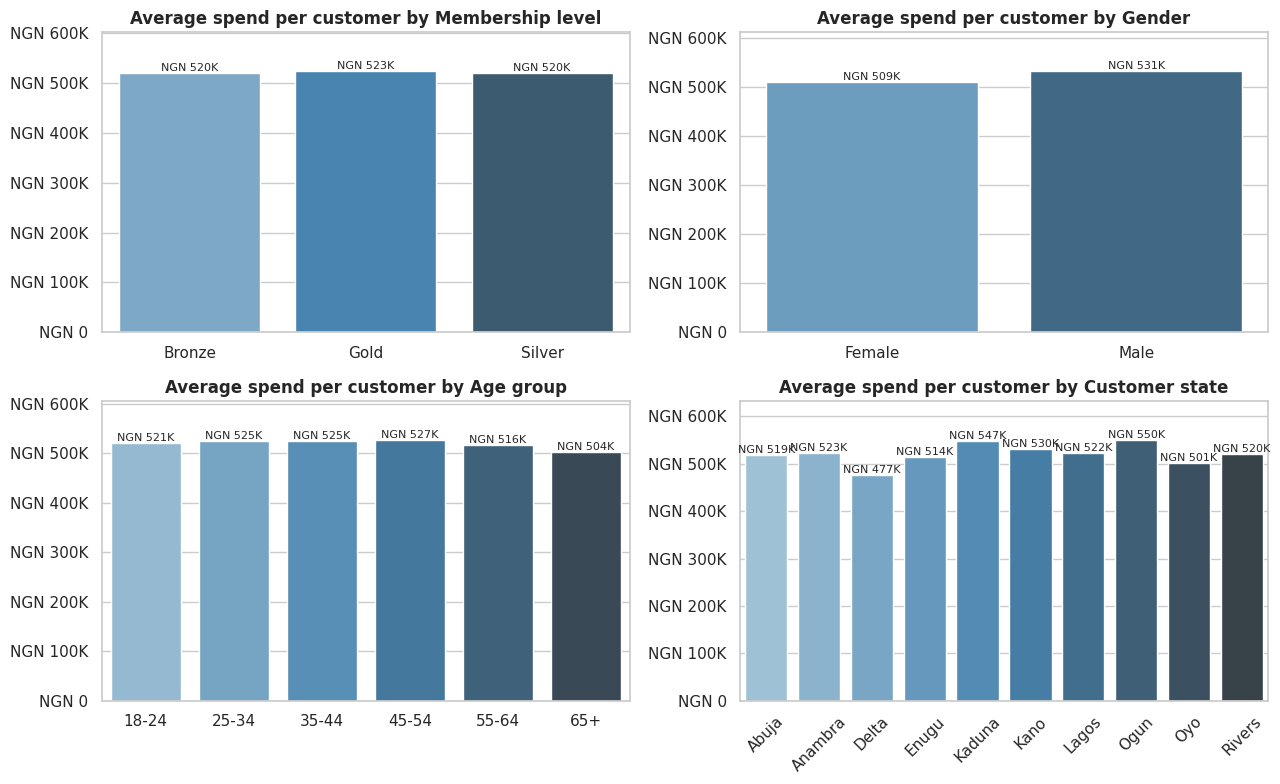

,customer_id,membership_level,customer_state,completed_orders,total_spend
3256,CUST03257,Silver,Oyo,10.00,NGN 2.3M
1670,CUST01671,Bronze,Ogun,10.00,NGN 2.2M
3049,CUST03050,Bronze,Kaduna,7.00,NGN 2.1M
1720,CUST01721,Gold,Abuja,9.00,NGN 2.1M
2252,CUST02253,Silver,Enugu,7.00,NGN 2.1M
2343,CUST02344,Silver,Abuja,8.00,NGN 2.1M
4266,CUST04267,Silver,Anambra,9.00,NGN 1.9M
1247,CUST01248,Gold,Kano,7.00,NGN 1.9M
3519,CUST03520,Bronze,Kano,10.00,NGN 1.8M
3346,CUST03347,Bronze,Enugu,7.00,NGN 1.8M


Top 10% of customers account for 24.8% of revenue.


In [33]:
active = cust_fe[cust_fe["has_purchased"] == 1]
seg_cols = {"Membership level": "membership_level", "Gender": "gender", "Age group": "customer_age_group", "Customer state": "customer_state"}
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (title, col) in zip(axes.ravel(), seg_cols.items()):
    seg = active.groupby(col, observed=True).agg(customers=("customer_id", "count"), revenue=("total_spend", "sum"), avg_spend=("total_spend", "mean")).reset_index()
    seg[col] = seg[col].astype(str)
    sns.barplot(data=seg, x=col, y="avg_spend", hue=col, palette="Blues_d", legend=False, ax=ax)
    for i, v in enumerate(seg["avg_spend"]): ax.text(i, v, money(v), ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, seg["avg_spend"].max() * 1.15); ax.yaxis.set_major_formatter(money_axis); ax.set_title(f"Average spend per customer by {title}", fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
    if col == "customer_state": ax.tick_params(axis="x", rotation=45)
    print(f"{title}: highest = {seg.loc[seg.avg_spend.idxmax(), col]} ({money(seg.avg_spend.max())}), lowest = {seg.loc[seg.avg_spend.idxmin(), col]} ({money(seg.avg_spend.min())}), "
          f"gap = {seg.avg_spend.max() / seg.avg_spend.min() - 1:.1%}")
save_fig("13_customer_segments")

# Top spenders and concentration
top_c = cust_fe.sort_values("total_spend", ascending=False).head(10)
display(top_c[["customer_id", "membership_level", "customer_state", "completed_orders", "total_spend"]].assign(total_spend=lambda d: d["total_spend"].map(money)))
share_top10 = cust_fe.sort_values("total_spend", ascending=False).head(int(len(cust_fe) * .1))["total_spend"].sum() / cust_fe["total_spend"].sum()
print(f"Top 10% of customers account for {share_top10:.1%} of revenue.")

**Answer:** differences between customer groups are small.
* **Membership level:** Gold (NGN 523K per customer), Silver (NGN 520K) and Bronze are within 0.6% of each other. The tiers **do not separate big spenders from small ones**.
* **Gender:** men average NGN 531K and women NGN 509K, a 4.3% gap.
* **Age group:** 45-54 spends the most (NGN 527K) and 65+ the least (NGN 504K).
* **State:** the widest gap, Ogun (NGN 550K) against Delta (NGN 477K) at 15.3%, still involves only about 500 customers per state.
* **Concentration:** the top 10% of customers generate 24.8% of revenue, a moderate concentration. The single biggest spenders (for example CUST03257, NGN 2.3M over 10 orders) are spread across all tiers and states.

### Q4. Which products have high return rates?

,product_id,product_name,category,orders,returned,refunds,return_rate
262,PROD0263,Home Item 263,Home,95,11,NGN 279K,11.6%
261,PROD0262,Beauty Item 262,Beauty,88,10,NGN 275K,11.4%
442,PROD0443,Beauty Item 443,Beauty,92,10,NGN 177K,10.9%
348,PROD0349,Fashion Item 349,Fashion,94,10,NGN 192K,10.6%
4,PROD0005,Home Item 5,Home,96,10,NGN 172K,10.4%
190,PROD0191,Beauty Item 191,Beauty,89,9,NGN 259K,10.1%
141,PROD0142,Home Item 142,Home,91,9,NGN 230K,9.9%
270,PROD0271,Beauty Item 271,Beauty,92,9,NGN 221K,9.8%
5,PROD0006,Beauty Item 6,Beauty,73,7,NGN 169K,9.6%
164,PROD0165,Electronics Item 165,Electronics,96,9,NGN 213K,9.4%


Average product has 100 orders and 4.9 returns.
Do return rates differ between products beyond chance? chi-square p = 0.952 -> NO significant difference (consistent with random variation)


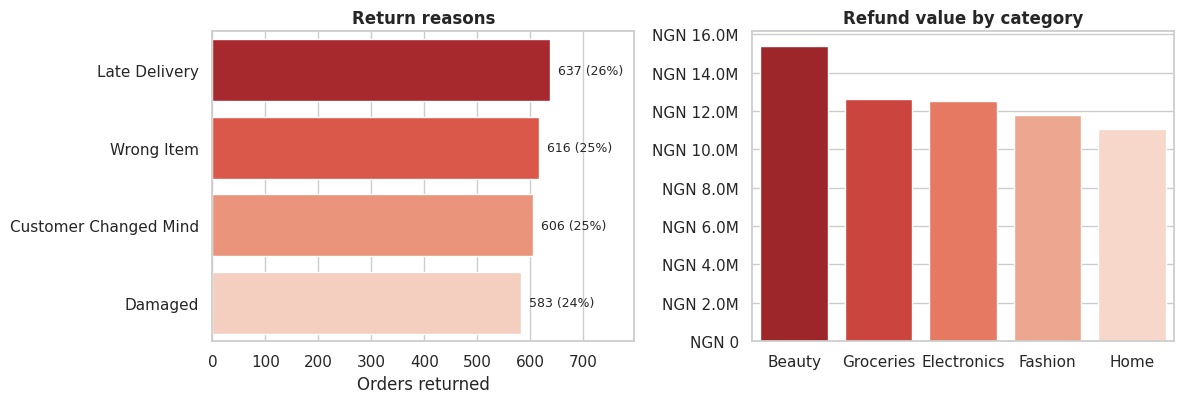

Share of return records on orders that were NOT Completed: 67.3% (data-quality caveat)
Total refunds recorded: NGN 63.4M = 2.5% of completed revenue


In [34]:
prod_ret = (master_fe.groupby(["product_id", "product_name", "category"], observed=True)
            .agg(orders=("order_id", "count"), returned=("is_returned", "sum"), refunds=("refund_total", "sum")).reset_index())
prod_ret["return_rate"] = prod_ret["returned"] / prod_ret["orders"]
display(prod_ret.sort_values(["return_rate", "returned"], ascending=False).head(10)
        .assign(return_rate=lambda d: d["return_rate"].map("{:.1%}".format), refunds=lambda d: d["refunds"].map(money)))

chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(master_fe["product_id"], master_fe["is_returned"]))
print(f"Average product has {prod_ret['orders'].mean():.0f} orders and {prod_ret['returned'].mean():.1f} returns.")
print(f"Do return rates differ between products beyond chance? chi-square p = {p:.3f} -> {verdict(p)}")

reasons = master_fe[master_fe["is_returned"] == 1]["return_reason"].astype(str).value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.barplot(x=reasons.values, y=reasons.index, hue=reasons.index, palette="Reds_r", legend=False, ax=axes[0])
for i, v in enumerate(reasons.values): axes[0].text(v, i, f"  {v} ({v / reasons.sum():.0%})", va="center", fontsize=9)
axes[0].set_xlim(0, reasons.max() * 1.25); axes[0].set_title("Return reasons", fontweight="bold"); axes[0].set_xlabel("Orders returned"); axes[0].set_ylabel("")
refund_cat = master_fe.groupby("category", observed=True)["refund_total"].sum().sort_values(ascending=False)
sns.barplot(x=refund_cat.index.astype(str), y=refund_cat.values, hue=refund_cat.index.astype(str), palette="Reds_r", legend=False, ax=axes[1])
axes[1].yaxis.set_major_formatter(money_axis); axes[1].set_title("Refund value by category", fontweight="bold"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
save_fig("14_return_reasons_and_refunds")
print(f"Share of return records on orders that were NOT Completed: {(master_fe[master_fe.is_returned == 1]['order_status'] != 'Completed').mean():.1%} (data-quality caveat)")
print(f"Total refunds recorded: {money(master_fe['refund_total'].sum())} = {master_fe['refund_total'].sum() / K['total_revenue']:.1%} of completed revenue")

**Answer:** no product stands out. The highest rates (Home Item 263 at 11.6%, Beauty Item 262 at 11.4%) rest on only 10 to 11 returns from about 90 orders each, which is what chance produces around a 4.9% average. The test confirms product differences are not real (p = 0.95).

**What the data does say about returns:**
* The reasons are evenly split: Late Delivery 26.0%, Wrong Item 25.2%, Customer Changed Mind 25.0%, Damaged 23.8%. **About 75% have operational causes** ShopSmart can influence (delivery, picking accuracy, packaging).
* Recorded refunds total NGN 63.4M, 2.5% of completed revenue.
* **Caveat:** 67.3% of return records are attached to orders that were never Completed, and about half are dated before their order. Return data needs validating with ShopSmart before it drives decisions.

### Q5. Which months have peak sales?

In [35]:
m = (completed.groupby(["order_month", "order_month_name"]).agg(revenue=("line_total", "sum"), orders=("order_id", "count")).reset_index())
m["days"] = [pd.Period(f"2025-{mo:02d}").days_in_month for mo in m["order_month"]]
m["revenue_per_day"] = m["revenue"] / m["days"]
m["vs_avg_month"] = m["revenue"] / m["revenue"].mean() - 1
print("Months ranked by revenue:")
display(m.sort_values("revenue", ascending=False).assign(revenue=lambda d: d["revenue"].map(money), revenue_per_day=lambda d: d["revenue_per_day"].map(money),
                                                          vs_avg_month=lambda d: d["vs_avg_month"].map("{:+.1%}".format)).drop(columns="order_month"))
q = completed.groupby("order_quarter").agg(revenue=("line_total", "sum"), orders=("order_id", "count"))
print("Quarterly revenue:"); display(q.assign(revenue=lambda d: d["revenue"].map(money)).T)
wd = completed.groupby("order_weekday")["line_total"].sum().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
print(f"Spread between busiest and quietest month: {m.revenue.max() / m.revenue.min() - 1:.1%}; "
      f"after adjusting for days in the month (revenue per day): {m.revenue_per_day.max() / m.revenue_per_day.min() - 1:.1%}")
print(f"Busiest weekday: {wd.idxmax()} ({money(wd.max())}); quietest: {wd.idxmin()} ({money(wd.min())})")

Months ranked by revenue:


,order_month_name,revenue,orders,days,revenue_per_day,vs_avg_month
11,Dec,NGN 224.7M,1415,31,NGN 7.2M,+8.0%
9,Oct,NGN 219.6M,1417,31,NGN 7.1M,+5.5%
0,Jan,NGN 214.5M,1424,31,NGN 6.9M,+3.1%
2,Mar,NGN 212.7M,1413,31,NGN 6.9M,+2.2%
3,Apr,NGN 210.7M,1408,30,NGN 7.0M,+1.3%
6,Jul,NGN 209.0M,1415,31,NGN 6.7M,+0.5%
10,Nov,NGN 207.6M,1387,30,NGN 6.9M,-0.2%
8,Sep,NGN 206.3M,1357,30,NGN 6.9M,-0.8%
7,Aug,NGN 204.0M,1360,31,NGN 6.6M,-2.0%
4,May,NGN 203.4M,1346,31,NGN 6.6M,-2.2%


Quarterly revenue:


order_quarter,Q1,Q2,Q3,Q4
revenue,NGN 617.0M,NGN 608.6M,NGN 619.4M,NGN 651.8M
orders,4098,4080,4132,4219


Spread between busiest and quietest month: 18.4%; after adjusting for days in the month (revenue per day): 11.8%
Busiest weekday: Thursday (NGN 372.8M); quietest: Sunday (NGN 341.0M)


**Answer:** **December** is the peak month (NGN 224.7M, +8.0% above the monthly average), followed by October (NGN 219.6M) and January (NGN 214.5M). February (NGN 189.8M) and June (NGN 194.5M) are the weakest.

February's low is largely a calendar effect: per day it earns NGN 6.8M against NGN 7.2M in December, so the peak-to-trough spread shrinks from 18.4% to 11.8% once month length is removed. **Q4 is the strongest quarter** (NGN 651.8M, about 6% above the average of Q1 to Q3). Thursday is the busiest weekday and Sunday the quietest. Overall seasonality is mild (monthly variation of only 4.7%).

### Q6. Which categories are growing?

,category,Q1_revenue,Q4_revenue,Q4_vs_Q1_%,H2_vs_H1_%,trend_per_month_%,trend_p_value
2,Fashion,NGN 113.1M,NGN 124.8M,10.32,6.41,1.22,0.08
0,Beauty,NGN 143.9M,NGN 155.6M,8.11,4.42,0.85,0.34
4,Home,NGN 106.2M,NGN 111.0M,4.50,2.15,0.28,0.65
1,Electronics,NGN 122.0M,NGN 127.0M,4.10,2.34,0.18,0.78
3,Groceries,NGN 131.8M,NGN 133.5M,1.29,3.26,0.11,0.87


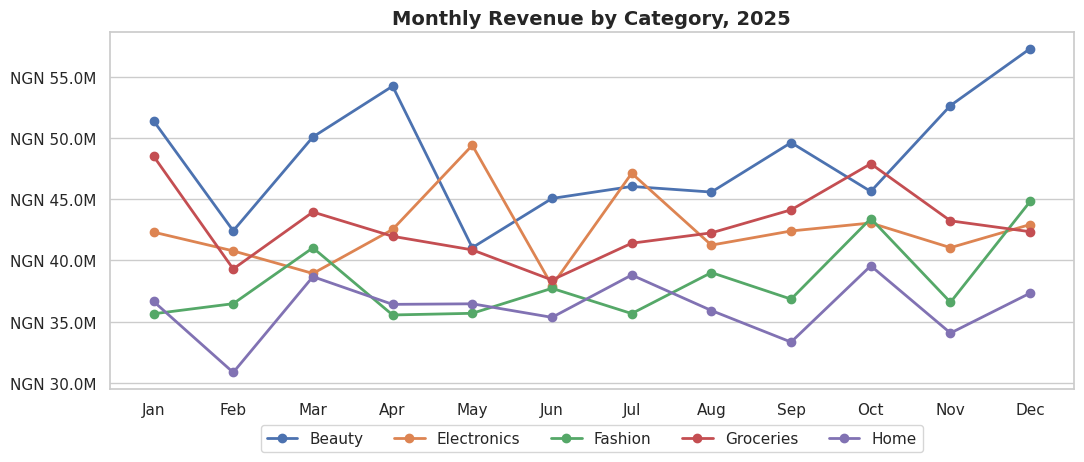

Categories with a statistically significant monthly trend (p < 0.05): none


In [36]:
cm = (completed.groupby(["order_month", "category"], observed=True)["line_total"].sum().reset_index())
pivot = cm.pivot(index="order_month", columns="category", values="line_total")
growth = []
for cat in pivot.columns:
    s = pivot[cat]
    slope, intercept, r, p, se = stats.linregress(s.index, s.values)
    growth.append({"category": str(cat), "Q1_revenue": s.loc[1:3].sum(), "Q4_revenue": s.loc[10:12].sum(),
                   "Q4_vs_Q1_%": 100 * (s.loc[10:12].sum() / s.loc[1:3].sum() - 1),
                   "H2_vs_H1_%": 100 * (s.loc[7:12].sum() / s.loc[1:6].sum() - 1),
                   "trend_per_month_%": 100 * slope / s.mean(), "trend_p_value": p})
growth = pd.DataFrame(growth).sort_values("Q4_vs_Q1_%", ascending=False)
display(growth.assign(Q1_revenue=lambda d: d["Q1_revenue"].map(money), Q4_revenue=lambda d: d["Q4_revenue"].map(money)).round(2))

fig, ax = plt.subplots(figsize=(11, 4.8))
for cat in pivot.columns: ax.plot(pivot.index, pivot[cat], marker="o", lw=2, label=str(cat))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.yaxis.set_major_formatter(money_axis); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(.5, -.08)); ax.grid(axis="x", visible=False)
ax.set_title("Monthly Revenue by Category, 2025", fontsize=14, fontweight="bold")
save_fig("15_category_monthly_trends")
print("Categories with a statistically significant monthly trend (p < 0.05):", growth.loc[growth["trend_p_value"] < .05, "category"].tolist() or "none")

**Answer:** comparing Q4 with Q1, **Fashion** grew fastest (+10.3%), then Beauty (+8.1%), Home (+4.5%), Electronics (+4.1%) and Groceries (+1.3%). All five categories grew, so the whole business edged upward through the year.

**Caution:** none of the monthly trends is statistically significant (the smallest p-value is 0.08, for Fashion). Treat these as *early signals to watch*, not established growth. With only 12 months of data, seasonality cannot be told apart from a trend.

### Q7. Which suppliers perform best?
The data has no delivery or lead-time fields, so "performance" can only be judged by the **sales** of the products each supplier provides and their **return** record. Products are linked to suppliers through the brand name (see Part 3).

In [37]:
sup_perf = (master_fe.groupby(["supplier_id", "supplier_name", "supplier_country"], observed=True)
            .agg(products=("product_id", "nunique"), orders=("order_id", "count"), returned=("is_returned", "sum")).reset_index())
sup_rev = completed.groupby("supplier_id").agg(revenue=("line_total", "sum"), units=("quantity", "sum")).reset_index()
sup_perf = sup_perf.merge(sup_rev, on="supplier_id", how="left")
sup_perf["return_rate"] = sup_perf["returned"] / sup_perf["orders"]
print("Distribution of products per supplier:", sup_perf["products"].value_counts().sort_index().to_dict())
print("\nSuppliers supplying the most products:")
display(sup_perf.sort_values(["products", "revenue"], ascending=False).head(8)[["supplier_name", "supplier_country", "products", "revenue", "return_rate"]]
        .assign(revenue=lambda d: d["revenue"].map(money), return_rate=lambda d: d["return_rate"].map("{:.1%}".format)))
print("Top 10 suppliers by revenue:")
display(sup_perf.sort_values("revenue", ascending=False).head(10)[["supplier_name", "supplier_country", "products", "revenue", "units", "return_rate"]]
        .assign(revenue=lambda d: d["revenue"].map(money), return_rate=lambda d: d["return_rate"].map("{:.1%}".format)))
ctry = sup_perf.groupby("supplier_country", observed=True).agg(suppliers=("supplier_id", "count"), revenue=("revenue", "sum"), returned=("returned", "sum"), orders=("orders", "sum"))
ctry["return_rate"] = ctry["returned"] / ctry["orders"]
print("By supplier country:"); display(ctry.assign(revenue=lambda d: d["revenue"].map(money), return_rate=lambda d: d["return_rate"].map("{:.2%}".format)))

Distribution of products per supplier: {1: 478, 2: 11}

Suppliers supplying the most products:


,supplier_name,supplier_country,products,revenue,return_rate
38,Thomas Ltd Supplies,USA,2,NGN 11.5M,4.7%
221,Williams Group Supplies,Germany,2,NGN 10.4M,5.2%
157,Martinez Ltd Supplies,USA,2,NGN 10.2M,5.7%
205,Matthews and Sons Supplies,China,2,NGN 10.1M,4.1%
173,Smith LLC Supplies,Germany,2,NGN 9.6M,3.9%
374,Smith PLC Supplies,China,2,NGN 9.6M,3.9%
37,Jones Group Supplies,Germany,2,NGN 9.3M,5.4%
99,Garcia PLC Supplies,Nigeria,2,NGN 9.2M,3.0%


Top 10 suppliers by revenue:


,supplier_name,supplier_country,products,revenue,units,return_rate
38,Thomas Ltd Supplies,USA,2,NGN 11.5M,221,4.7%
221,Williams Group Supplies,Germany,2,NGN 10.4M,200,5.2%
157,Martinez Ltd Supplies,USA,2,NGN 10.2M,191,5.7%
205,Matthews and Sons Supplies,China,2,NGN 10.1M,194,4.1%
173,Smith LLC Supplies,Germany,2,NGN 9.6M,203,3.9%
374,Smith PLC Supplies,China,2,NGN 9.6M,191,3.9%
37,Jones Group Supplies,Germany,2,NGN 9.3M,178,5.4%
99,Garcia PLC Supplies,Nigeria,2,NGN 9.2M,195,3.0%
16,Dyer LLC Supplies,China,2,NGN 9.2M,174,7.2%
107,Myers and Sons Supplies,Germany,2,NGN 9.0M,190,4.8%


By supplier country:


,suppliers,revenue,returned,orders,return_rate
supplier_country,,,,,
China,122,NGN 615.1M,562,12367,4.54%
Germany,127,NGN 663.5M,663,13305,4.98%
Nigeria,118,NGN 609.6M,587,12037,4.88%
USA,122,NGN 608.6M,630,12291,5.13%


**Answer:** supplier "performance" can only be judged on sales and returns, because the data has no delivery or lead-time fields. A question like "which supplier has delayed deliveries" cannot be answered with this dataset.
* **Number of products:** 478 of 489 suppliers supply exactly one product and 11 supply two. No supplier stands out on volume of products.
* **Revenue:** the top suppliers are Thomas Ltd Supplies (USA, NGN 11.5M, 2 products), Williams Group Supplies (Germany, NGN 10.4M) and Martinez Ltd Supplies (USA, NGN 10.2M).
* **By country:** Germany-based suppliers earn the most (NGN 663.5M), then China (NGN 615.1M), Nigeria (NGN 609.6M) and USA (NGN 608.6M). Return rates are similar (4.5% for China to 5.1% for USA).

### Q8. Which inventory items require restocking?

21 of 500 stock records are at or below their reorder level (4.2%). Most urgent first:


,inventory_id,product_id,product_name,category,store_id,store_city,stock_on_hand,reorder_level,units_below_reorder,stock_cover_ratio
211,INV00212,PROD0212,Home Item 212,Home,STR022,Awka,12,41,29,0.29
413,INV00414,PROD0414,Home Item 414,Home,STR009,Ibadan,13,44,31,0.30
301,INV00302,PROD0302,Home Item 302,Home,STR013,Lagos,14,46,32,0.30
164,INV00165,PROD0165,Electronics Item 165,Electronics,STR014,Port Harcourt,14,45,31,0.31
478,INV00479,PROD0479,Beauty Item 479,Beauty,STR017,Abuja,10,29,19,0.34
370,INV00371,PROD0371,Beauty Item 371,Beauty,STR018,Ibadan,16,41,25,0.39
145,INV00146,PROD0146,Electronics Item 146,Electronics,STR021,Lagos,21,47,26,0.45
58,INV00059,PROD0059,Fashion Item 59,Fashion,STR002,Kano,11,23,12,0.48
271,INV00272,PROD0272,Fashion Item 272,Fashion,STR001,Abuja,16,29,13,0.55
477,INV00478,PROD0478,Home Item 478,Home,STR006,Kaduna,28,50,22,0.56



Low-stock items by category: {'Home': 6, 'Beauty': 5, 'Fashion': 5, 'Electronics': 4, 'Groceries': 1}
Low-stock items by store (top): {'STR014': 3, 'STR006': 3, 'STR009': 2, 'STR018': 2, 'STR001': 2}


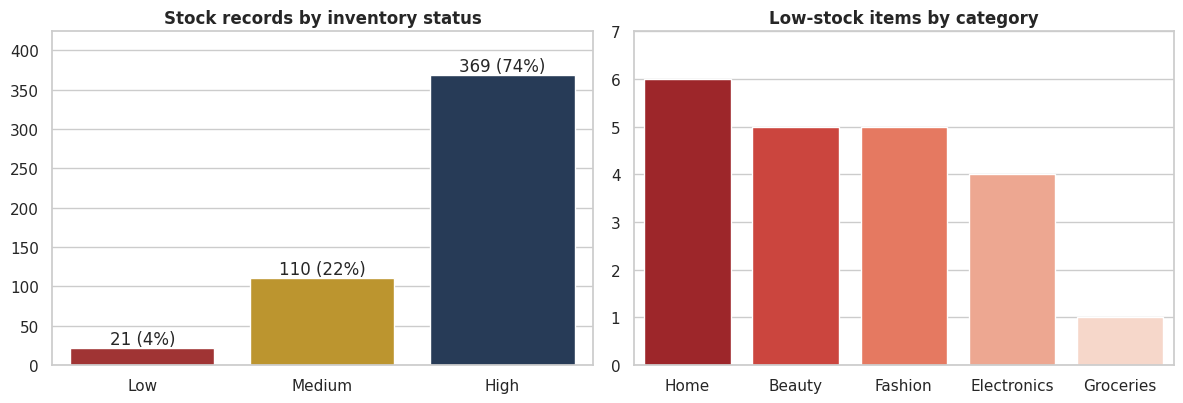

Note: each product appears at only one store in the inventory table, so 'restock' means that single record.


In [38]:
low = inv_fe[inv_fe["inventory_status"] == "Low"].sort_values("stock_cover_ratio")
print(f"{len(low)} of {len(inv_fe)} stock records are at or below their reorder level "
      f"({len(low) / len(inv_fe):.1%}). Most urgent first:")
display(low[["inventory_id", "product_id", "product_name", "category", "store_id", "store_city", "stock_on_hand", "reorder_level", "units_below_reorder", "stock_cover_ratio"]].head(21))
print("\nLow-stock items by category:", low["category"].astype(str).value_counts().to_dict())
print("Low-stock items by store (top):", low["store_id"].value_counts().head(5).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
st = inv_fe["inventory_status"].value_counts().reindex(["Low", "Medium", "High"])
sns.barplot(x=st.index.astype(str), y=st.values, hue=st.index.astype(str), palette=["firebrick", BRAND_GOLD, BRAND_BLUE], legend=False, ax=axes[0])
for i, v in enumerate(st.values): axes[0].text(i, v, f"{v} ({v / st.sum():.0%})", ha="center", va="bottom")
axes[0].set_title("Stock records by inventory status", fontweight="bold"); axes[0].set_xlabel(""); axes[0].set_ylim(0, st.max() * 1.15)
lc = low["category"].astype(str).value_counts()
sns.barplot(x=lc.index, y=lc.values, hue=lc.index, palette="Reds_r", legend=False, ax=axes[1])
axes[1].set_title("Low-stock items by category", fontweight="bold"); axes[1].set_xlabel(""); axes[1].set_yticks(range(0, int(lc.max()) + 2))
save_fig("16_inventory_status")
print("Note: each product appears at only one store in the inventory table, so 'restock' means that single record.")

**Answer:** **21 stock records (4.2%) are at or below their reorder level** and need restocking now. The most urgent are Home Item 212 at STR022 Awka (12 units against a reorder level of 41), Home Item 414 at STR009 Ibadan (13 against 44), Home Item 302 at STR013 Lagos (14 against 46) and Electronics Item 165 at STR014 Port Harcourt (14 against 45). By category, Home has 6 low items, Beauty and Fashion 5 each, Electronics 4 and Groceries 1. STR014 and STR006 have three low items each.

**The bigger issue is the opposite one:** 73.8% of stock records hold more than five times their reorder level, and they account for NGN 2.95B of the NGN 3.17B total inventory value. Over-stocking ties up far more cash than the small number of stock-outs.

### Q9. Which regions underperform?
Regions have different numbers of stores, so total revenue is misleading. Revenue **per store** is the fair comparison.

,region,revenue,orders,aov,stores,revenue_per_store,return_rate
1,North,NGN 608.2M,3937,NGN 154K,6,NGN 101.4M,4.56%
2,South,NGN 805.4M,5303,NGN 152K,8,NGN 100.7M,4.98%
0,East,NGN 694.2M,4657,NGN 149K,7,NGN 99.2M,5.13%
3,West,NGN 389.0M,2632,NGN 148K,4,NGN 97.3M,4.73%


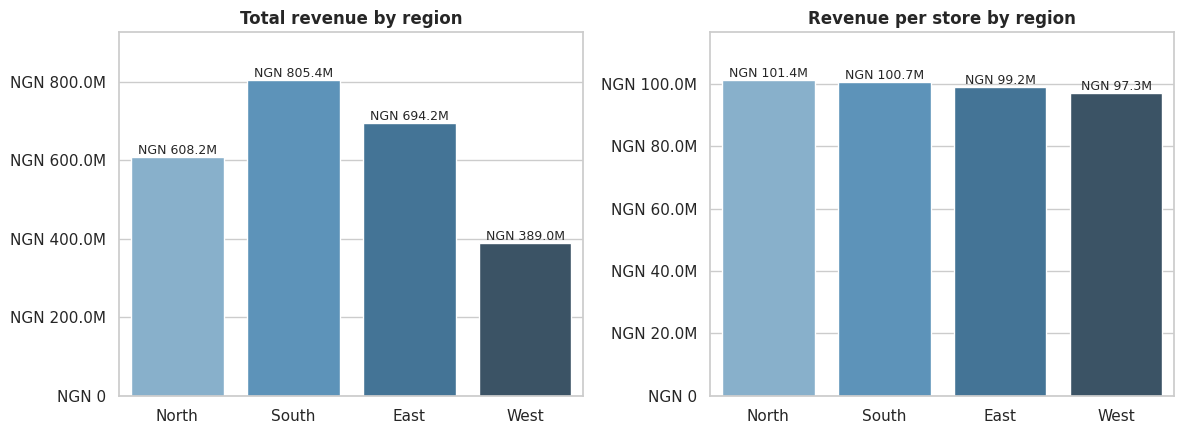

Gap between best and weakest region per store: 4.2%


In [39]:
reg = (completed.groupby("region", observed=True)
       .agg(revenue=("line_total", "sum"), orders=("order_id", "count"), aov=("line_total", "mean"), stores=("store_id", "nunique")).reset_index())
reg["revenue_per_store"] = reg["revenue"] / reg["stores"]
reg_ret = master_fe.groupby("region", observed=True)["is_returned"].mean().rename("return_rate").reset_index()
reg = reg.merge(reg_ret, on="region").sort_values("revenue_per_store", ascending=False)
reg["region"] = reg["region"].astype(str)          # plain strings so bars and labels share the same order
display(reg.assign(revenue=lambda d: d["revenue"].map(money), aov=lambda d: d["aov"].map(money),
                   revenue_per_store=lambda d: d["revenue_per_store"].map(money), return_rate=lambda d: d["return_rate"].map("{:.2%}".format)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, title in [(axes[0], "revenue", "Total revenue by region"), (axes[1], "revenue_per_store", "Revenue per store by region")]:
    sns.barplot(data=reg, x="region", y=col, order=reg["region"], hue="region", palette="Blues_d", legend=False, ax=ax)
    for i, v in enumerate(reg[col]): ax.text(i, v, money(v), ha="center", va="bottom", fontsize=9)
    ax.yaxis.set_major_formatter(money_axis); ax.set_ylim(0, reg[col].max() * 1.15); ax.set_title(title, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
save_fig("17_region_performance")
print(f"Gap between best and weakest region per store: {reg.revenue_per_store.max() / reg.revenue_per_store.min() - 1:.1%}")

**Answer:** **no region underperforms materially.** Total revenue is lowest in the **West** (NGN 389.0M) and highest in the South (NGN 805.4M), but only because the West has 4 stores against the South's 8. Per store the regions are within 4.2% of each other: North NGN 101.4M, South NGN 100.7M, East NGN 99.2M and West NGN 97.3M. The West also has the lowest average order value (NGN 148K), so it is the one to watch, but the difference is not statistically significant. Regions in this dataset do not follow real geography (the same state appears in up to four regions), so regional conclusions should be confirmed with ShopSmart.

### Q10. What patterns could support predictive modelling?
Rather than guess, this block tests how much predictable signal the data actually contains for four candidate modelling problems.

In [40]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

findings = {}
# (a) Order value: how well do price and quantity explain line_total?
X = master_fe[["quantity", "unit_price", "discount"]]; y = master_fe["line_total"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=42)
findings["Order value (regression) from quantity, price, discount: R2"] = r2_score(yte, LinearRegression().fit(Xtr, ytr).predict(Xte))
Xi = master_fe.assign(price_x_qty=master_fe["quantity"] * master_fe["unit_price"])[["price_x_qty"]]
findings["Order value using the product quantity x price: R2"] = r2_score(yte, LinearRegression().fit(Xi.loc[Xtr.index], ytr).predict(Xi.loc[Xte.index]))

# (b) Return prediction: can customer, product, store and order attributes predict a return?
feat = pd.get_dummies(master_fe[["category", "sales_channel", "payment_method", "membership_level", "region", "gender"]].astype(str), drop_first=True)
feat[["quantity", "unit_price", "discount", "shipping_cost", "age"]] = master_fe[["quantity", "unit_price", "discount", "shipping_cost", "age"]]
Xtr, Xte, ytr, yte = train_test_split(feat, master_fe["is_returned"], test_size=.25, random_state=42, stratify=master_fe["is_returned"])
sc = StandardScaler().fit(Xtr)
clf = LogisticRegression(max_iter=500).fit(sc.transform(Xtr), ytr)
findings["Return prediction (logistic regression): ROC-AUC (0.50 = coin flip)"] = roc_auc_score(yte, clf.predict_proba(sc.transform(Xte))[:, 1])

# (c) Monthly seasonality
mrev = completed.groupby("order_month")["line_total"].sum()
findings["Seasonality: monthly revenue coefficient of variation (%)"] = 100 * mrev.std() / mrev.mean()

# (d) Customer behaviour: does age or tenure relate to spend?
act = cust_fe[cust_fe["has_purchased"] == 1]
findings["Customer spend vs age (Pearson r)"] = act["total_spend"].corr(act["age"])
findings["Customer spend vs tenure (Pearson r)"] = act["total_spend"].corr(act["customer_tenure_days"])
findings["Customer orders vs spend (Pearson r)"] = act["completed_orders"].corr(act["total_spend"])
display(pd.Series(findings, name="value").round(3).to_frame())

,value
"Order value (regression) from quantity, price, discount: R2",0.89
Order value using the product quantity x price: R2,1.00
Return prediction (logistic regression): ROC-AUC (0.50 = coin flip),0.49
Seasonality: monthly revenue coefficient of variation (%),4.67
Customer spend vs age (Pearson r),-0.01
Customer spend vs tenure (Pearson r),0.01
Customer orders vs spend (Pearson r),0.77


**What the data can and cannot support:**
* **Order value:** almost perfectly predictable from `quantity x unit_price` (R-squared 1.00) and 0.89 from a plain linear model on quantity, price and discount. This is arithmetic, not insight, so a model for it adds little value.
* **Returns:** a logistic regression using customer, product, store and order attributes scores a ROC-AUC of **0.49**, no better than a coin flip. With the current data a return-prediction model is **not viable**.
* **Seasonality:** weak (4.7% monthly variation), with a mild Q4 and December lift.
* **Customers:** order count and total spend move together (r = 0.77) while age and tenure are unrelated to spend (|r| <= 0.01). Behaviour (RFM) carries signal; demographics do not.

**Best candidates for machine learning:** customer segmentation and churn on RFM features, aggregate sales forecasting once more history exists, inventory replenishment, and rule-based anomaly detection for below-cost sales and impossible refunds.

## Bonus Challenge: Customer Segmentation with K-Means
**Goal:** group customers by purchasing behaviour using **RFM** (Recency, Frequency, Monetary), so marketing can treat groups differently. Only the customers with at least one completed purchase are used.

,k,inertia,silhouette
0,2,"8,197.85",0.37
1,3,"5,416.44",0.36
2,4,"4,321.15",0.32
3,5,"3,691.47",0.32
4,6,"3,213.61",0.30
5,7,"2,883.71",0.28
6,8,"2,648.85",0.28


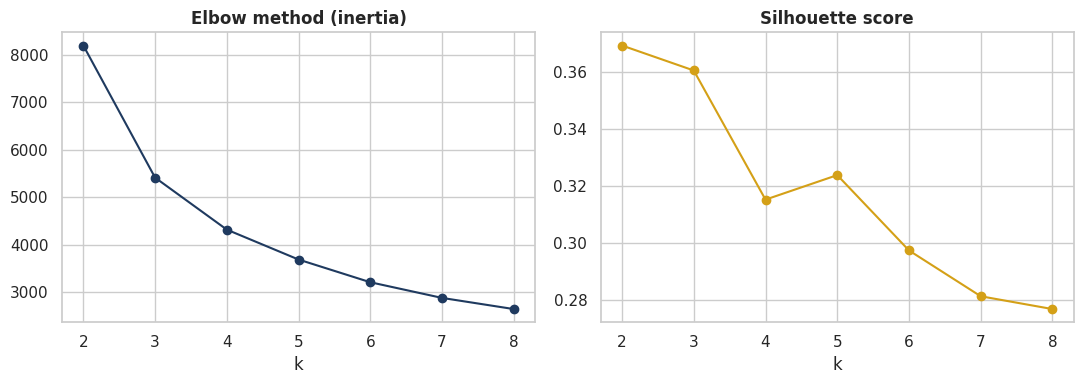

In [41]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

rfm = cust_fe.loc[cust_fe["has_purchased"] == 1, ["customer_id", "days_since_last_purchase", "completed_orders", "total_spend"]].copy()
rfm.columns = ["customer_id", "recency_days", "frequency", "monetary"]
X = StandardScaler().fit_transform(rfm[["recency_days", "frequency", "monetary"]])

# Choose k with the elbow (inertia) and the silhouette score
results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    results.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_, sample_size=3000, random_state=42)})
results = pd.DataFrame(results)
display(results.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(results["k"], results["inertia"], marker="o", color=BRAND_BLUE); axes[0].set_title("Elbow method (inertia)", fontweight="bold"); axes[0].set_xlabel("k")
axes[1].plot(results["k"], results["silhouette"], marker="o", color=BRAND_GOLD); axes[1].set_title("Silhouette score", fontweight="bold"); axes[1].set_xlabel("k")
save_fig("18_kmeans_choose_k")

,customers,recency_days,frequency,monetary,total_revenue,share_of_customers,share_of_revenue
segment,,,,,,,
Champions,691,49.60,6.40,NGN 1.1M,NGN 772.8M,14.4%,31.0%
Loyal regulars,1652,61.60,4.10,NGN 633K,NGN 1.05B,34.5%,41.9%
Occasional buyers,1498,66.80,2.30,NGN 277K,NGN 415.2M,31.2%,16.6%
At risk / lapsed,954,233.40,2.00,NGN 275K,NGN 262.3M,19.9%,10.5%


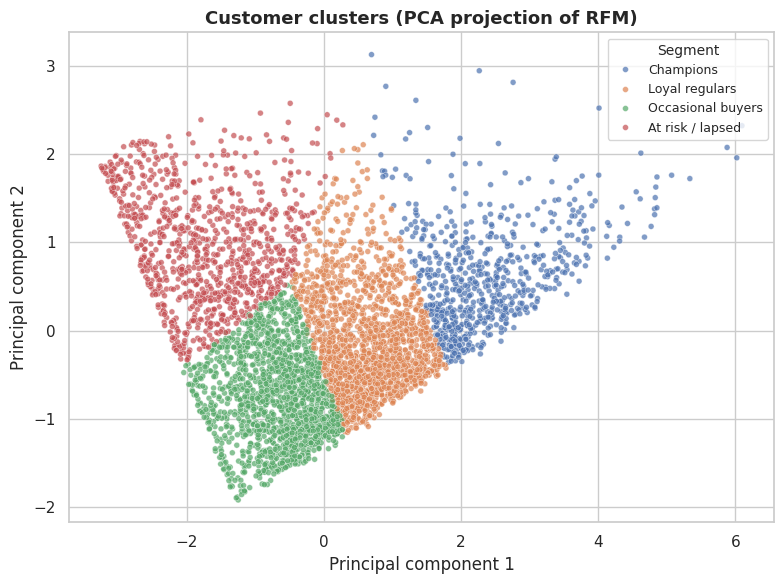

silhouette for chosen k: 0.315


In [42]:
K_CLUSTERS = 4          # chosen for business usability; the silhouette table above shows how weakly the data separates
km = KMeans(n_clusters=K_CLUSTERS, n_init=10, random_state=42).fit(X)
rfm["cluster"] = km.labels_

# Name each cluster from its own profile (rules, not hard-coded IDs, so names survive a re-run)
prof = rfm.groupby("cluster")[["recency_days", "frequency", "monetary"]].mean()
names = {prof["monetary"].idxmax(): "Champions"}
names[prof.drop(index=list(names))["recency_days"].idxmax()] = "At risk / lapsed"
rest = prof.drop(index=list(names)).sort_values("monetary", ascending=False).index
names[rest[0]], names[rest[1]] = "Loyal regulars", "Occasional buyers"
rfm["segment"] = rfm["cluster"].map(names)

profile = rfm.groupby("segment").agg(customers=("customer_id", "count"), recency_days=("recency_days", "mean"),
                                    frequency=("frequency", "mean"), monetary=("monetary", "mean"), total_revenue=("monetary", "sum"))
profile["share_of_customers"] = profile["customers"] / profile["customers"].sum()
profile["share_of_revenue"]   = profile["total_revenue"] / profile["total_revenue"].sum()
profile = profile.sort_values("monetary", ascending=False)
display(profile.assign(monetary=lambda d: d["monetary"].map(money), total_revenue=lambda d: d["total_revenue"].map(money),
                       share_of_customers=lambda d: d["share_of_customers"].map("{:.1%}".format), share_of_revenue=lambda d: d["share_of_revenue"].map("{:.1%}".format)).round(1))

coords = PCA(n_components=2, random_state=42).fit_transform(X)
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=rfm["segment"], palette="deep", hue_order=profile.index, s=18, alpha=.7, ax=ax)
ax.set_title("Customer clusters (PCA projection of RFM)", fontsize=13, fontweight="bold"); ax.set_xlabel("Principal component 1"); ax.set_ylabel("Principal component 2"); ax.legend(title="Segment", fontsize=9, title_fontsize=10, loc="upper right")
save_fig("19_customer_clusters")
rfm.to_csv(CLEAN_DIR / "customer_segments.csv", index=False)
print("silhouette for chosen k:", round(silhouette_score(X, km.labels_, sample_size=3000, random_state=42), 3))

**Result:** four segments with distinct behaviour:

| Segment | Customers | Orders per customer | Avg spend | Days since last purchase | Share of revenue |
|---|---|---|---|---|---|
| **Champions** | 691 (14.4%) | 6.4 | NGN 1.1M | 50 | 31.0% |
| **Loyal regulars** | 1,652 (34.5%) | 4.1 | NGN 633K | 62 | 41.9% |
| **Occasional buyers** | 1,498 (31.2%) | 2.3 | NGN 277K | 67 | 16.6% |
| **At risk / lapsed** | 954 (19.9%) | 2.0 | NGN 275K | 233 | 10.5% |

**Suggested actions:** protect and reward Champions, who give 31% of revenue from 14% of customers; grow Loyal regulars into Champions with targeted offers; nudge Occasional buyers toward a second purchase; run a win-back campaign for the At-risk group, who have not bought for about 233 days on average.

**Limitations:** the silhouette peaks at k = 2 (0.37) and is 0.32 at k = 4, meaning the groups are slices of a continuum rather than naturally separate clusters. k = 4 was chosen because it is more useful to the business. K-Means assumes roughly round clusters, the RFM values come from a single year, and the segments are unrelated to age, gender or membership tier.

## Part 9: Findings, Recommendations and Machine Learning Opportunities

### Five key insights
1. **Only one order in three is completed.** Of 50,000 orders, 33.1% are Completed, 33.7% Cancelled and 33.2% Pending. Cancelled orders hold NGN 2.55B and Pending orders NGN 2.53B of order value, against NGN 2.50B of realised revenue. Each extra percentage point of orders completed is worth about NGN 76M.
2. **Performance is remarkably even.** None of eight statistical tests found a real difference between stores, categories, regions, membership levels or channels. The best store is 13.6% above average, regions are within 4.2% per store, and category revenue per product ranges only from NGN 4.88M to NGN 5.15M. Rankings mostly reflect size, not quality.
3. **Data reliability limits what can be concluded.** The `discount` column behaves as a flat amount; if it was meant to be a percentage, revenue is overstated by about NGN 250M (11%). 24.3% of orders are priced below product cost, order prices do not match catalogue prices, about half of returns pre-date their order, 67% of returns belong to non-completed orders and 270 refunds exceed the order value.
4. **Customer value is moderately concentrated, and loyalty tiers do not work.** The top 10% of customers generate 24.8% of revenue, and Gold, Silver and Bronze customers spend within 0.6% of one another. K-Means shows 14.4% of customers (Champions) deliver 31.0% of revenue, while 19.9% have gone quiet for about 233 days.
5. **Inventory is out of balance.** 21 records (4.2%) are at or below reorder level, yet 73.8% hold more than five times their reorder level, representing NGN 2.95B of the NGN 3.17B inventory value, which is more than the NGN 2.50B of realised 2025 revenue.

*Other observations:* Q4 is the strongest quarter (about 6% above the Q1-Q3 average), December the peak month and Thursday the busiest day. About 75% of returns have operational causes (late delivery, wrong item, damage).

### Five recommendations
1. **Fix the order-completion funnel first.** Record a reason for every cancellation, set a time limit for Pending orders and track the completion rate weekly. This is the largest revenue opportunity in the data.
2. **Fix the data rules before building models.** Confirm how discounts work, where order prices come from (24% below cost), validate returns (after the order, Completed orders only, refund no larger than the sale), give stores unique names and real regions, add `supplier_id` to Products and complete the data dictionary (four tables have no entries).
3. **Restock the 21 low-stock items now and review overstock.** Start with Home Items 212, 414 and 302 and Electronics Item 165, and set an automatic alert using the `inventory_status` feature. Review the high-cover stock to release working capital.
4. **Win back lapsed customers and redesign the membership tiers.** Target the roughly 950 At-risk customers with a re-engagement offer, protect the Champions, and make Gold, Silver and Bronze reflect real spending so that tiers drive behaviour.
5. **Plan around Q4 and December, but do not reallocate stock or budget on small differences.** Prepare for the seasonal lift and weekday pattern. Wait for multi-year data before moving resources between stores, regions or categories, because current gaps are within random variation.

### Suggested machine learning problems
| Problem | Feasible with today's data? | Notes |
|---|---|---|
| **Customer segmentation** | **Yes** | RFM shows real structure (done in the bonus). |
| **Customer churn prediction** | Partly | RFM features are ready, but a churn definition (for example no purchase in 180 days) and more than one year of history are needed. |
| **Sales forecasting** | Partly | Works at aggregate level, but one year cannot confirm seasonality. Two to three years are needed. |
| **Inventory forecasting** | Not yet | Only a single stock snapshot exists, with no stock-movement history. |
| **Product recommendation** | Limited | Each order has one item, so there is no basket data, and customers average 3.3 completed orders. |
| **Return prediction** | **No** | ROC-AUC is 0.49 and the returns data has logic errors. Fix the data first. |
| **Anomaly detection** | Yes (rules first) | Below-cost sales, refunds above the sale and returns before purchase can be caught with simple rules. |

### Limitations of this analysis
* The data covers one year (2025) and appears synthetic or heavily simplified (uniform quantities, discounts, channels and statuses), so patterns may be weaker than in a real retail business.
* The currency is assumed to be NGN. Revenue counts Completed orders only; the gross alternative (NGN 7.58B) is reported alongside.
* There are no delivery, lead-time, promotion or basket-level fields, which limits supplier, return and recommendation analysis.

## Part 10: Code Quality and Reproducibility
* **Structure:** the notebook follows the brief's parts in order, each with a markdown explanation of purpose, method and result.
* **Modular code:** reusable functions (`money`, `save_fig`, `standardise_columns`, `engineer_order_features`, `engineer_customer_features`, `engineer_inventory_features`, `verdict`) avoid repeated logic.
* **Documented cleaning:** every cleaning action and every integrity failure is recorded in `Cleaned_Data/cleaning_log.csv` and `integrity_checks.csv`.
* **Safe merges:** every `merge` uses `validate=` and the row count is asserted, so a bad join would stop the notebook instead of silently duplicating orders.
* **Clear naming and assumptions:** lower_snake_case columns, descriptive variable names and every business assumption stated up front.
* **Reproducible:** fixed random seeds (`random_state=42`), pinned dependencies in `requirements.txt`, and all outputs regenerate by running *Kernel > Restart & Run All*.

**To re-run:** `pip install -r requirements.txt`, place the CSV files in `data/`, then run `jupyter notebook Week1_EDA.ipynb`.